 ## 1)Importing libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

## 2)Load dataset

In [2]:
df = pd.read_excel("marketing_campaign.xlsx")

df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


In [3]:
df.tail()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
2235,10870,1967,Graduation,Married,61223.0,0,1,2013-06-13,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,2014-06-10,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,2014-01-25,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,2014-01-24,8,428,...,3,0,0,0,0,0,0,3,11,0
2239,9405,1954,PhD,Married,52869.0,1,1,2012-10-15,40,84,...,7,0,0,0,0,0,0,3,11,1


In [4]:
df.sample(5)  ## Display random 5 records

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
1238,6918,1989,Graduation,Married,28691.0,1,0,2013-07-04,56,5,...,8,0,0,0,0,0,0,3,11,0
1011,5723,1976,PhD,Together,49187.0,0,1,2014-01-11,63,81,...,2,0,0,0,0,0,0,3,11,0
859,1031,1989,2n Cycle,Married,85710.0,0,0,2013-05-05,5,600,...,2,0,0,1,0,0,0,3,11,0
1565,1497,1952,Graduation,Single,47958.0,0,1,2013-01-19,8,268,...,5,0,0,0,0,0,0,3,11,0
625,3641,1976,Graduation,Married,13624.0,1,0,2013-01-20,93,10,...,6,0,0,0,0,0,0,3,11,0


## Dataset exploration

In [5]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 2240
Number of Columns: 29


## column names

In [6]:
print(df.columns.tolist())

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


## Dataset information

In [7]:
df.info()   ##Display dataset information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2240 non-null   int64         
 1   Year_Birth           2240 non-null   int64         
 2   Education            2240 non-null   object        
 3   Marital_Status       2240 non-null   object        
 4   Income               2216 non-null   float64       
 5   Kidhome              2240 non-null   int64         
 6   Teenhome             2240 non-null   int64         
 7   Dt_Customer          2240 non-null   datetime64[ns]
 8   Recency              2240 non-null   int64         
 9   MntWines             2240 non-null   int64         
 10  MntFruits            2240 non-null   int64         
 11  MntMeatProducts      2240 non-null   int64         
 12  MntFishProducts      2240 non-null   int64         
 13  MntSweetProducts     2240 non-nul

## Statistical summary

In [8]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,2013-07-10 10:01:42.857142784,49.109375,303.935714,26.302232,166.950000,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,2013-01-16 00:00:00,24.000000,23.750000,1.000000,16.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,2013-07-08 12:00:00,49.000000,173.500000,8.000000,67.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,2013-12-30 06:00:00,74.000000,504.250000,33.000000,232.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.000000,199.000000,1725.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,NaN,28.962453,336.597393,39.773434,225.715373,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274


## Categorical summary

In [9]:
df.describe(include='object')

,Education,Marital_Status
count,2240,2240
unique,5,8
top,Graduation,Married
freq,1127,864


## Unique values

In [10]:
for col in df.columns:
    print("\nColumn:", col)
    print("Unique values:", df[col].nunique())


Column: ID
Unique values: 2240

Column: Year_Birth
Unique values: 59

Column: Education
Unique values: 5

Column: Marital_Status
Unique values: 8

Column: Income
Unique values: 1974

Column: Kidhome
Unique values: 3

Column: Teenhome
Unique values: 3

Column: Dt_Customer
Unique values: 663

Column: Recency
Unique values: 100

Column: MntWines
Unique values: 776

Column: MntFruits
Unique values: 158

Column: MntMeatProducts
Unique values: 558

Column: MntFishProducts
Unique values: 182

Column: MntSweetProducts
Unique values: 177

Column: MntGoldProds
Unique values: 213

Column: NumDealsPurchases
Unique values: 15

Column: NumWebPurchases
Unique values: 15

Column: NumCatalogPurchases
Unique values: 14

Column: NumStorePurchases
Unique values: 14

Column: NumWebVisitsMonth
Unique values: 16

Column: AcceptedCmp3
Unique values: 2

Column: AcceptedCmp4
Unique values: 2

Column: AcceptedCmp5
Unique values: 2

Column: AcceptedCmp1
Unique values: 2

Column: AcceptedCmp2
Unique values: 2

Co

## Duplicate records

In [11]:
# Remove exact duplicate records from the original dataset
df = df.drop_duplicates()

remaining_duplicate_rows = int(df.duplicated().sum())

print("Dataset shape after duplicate removal:", df.shape)
print("Remaining exact duplicate records:", remaining_duplicate_rows)

Dataset shape after duplicate removal: (2240, 29)
Remaining exact duplicate records: 0


## Missing values analysis

In [12]:
# Missing values count and percentage
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df)) * 100
})

# Display only columns with missing values
missing = missing[missing['Missing_Count'] > 0]

display(missing)

,Missing_Count,Missing_Percentage
Income,24,1.071429


## Data Cleaning

### Missing values visualization

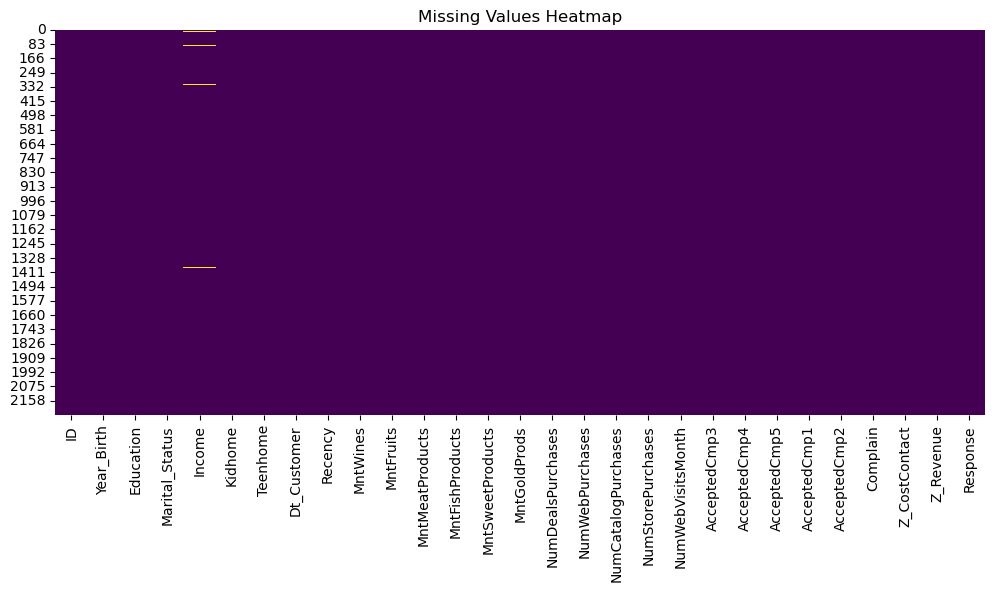

In [13]:
plt.figure(figsize=(12,5))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title("Missing Values Heatmap")
plt.show()

## Missing values treatment

In [14]:
print("Before:", df['Income'].isnull().sum())

df['Income'] = df['Income'].fillna(
    df['Income'].median()
)

print("After:", df['Income'].isnull().sum())

Before: 24
After: 0


## Check incorrect data types

In [15]:
print(df.columns.tolist())

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


In [16]:
# Check and correct data types

if 'Dt_Customer' in df.columns:

    df['Dt_Customer'] = pd.to_datetime(
        df['Dt_Customer'],
        errors='coerce',
        dayfirst=True
    )

    print("Dt_Customer converted successfully")

else:
    print("Dt_Customer column is not available")

print("\nUpdated Data Types:")
print(df.dtypes)

print("\nDate column data type:")
print(df['Dt_Customer'].dtype)

Dt_Customer converted successfully

Updated Data Types:
ID                              int64
Year_Birth                      int64
Education                      object
Marital_Status                 object
Income                        float64
Kidhome                         int64
Teenhome                        int64
Dt_Customer            datetime64[ns]
Recency                         int64
MntWines                        int64
MntFruits                       int64
MntMeatProducts                 int64
MntFishProducts                 int64
MntSweetProducts                int64
MntGoldProds                    int64
NumDealsPurchases               int64
NumWebPurchases                 int64
NumCatalogPurchases             int64
NumStorePurchases               int64
NumWebVisitsMonth               int64
AcceptedCmp3                    int64
AcceptedCmp4                    int64
AcceptedCmp5                    int64
AcceptedCmp1                    int64
AcceptedCmp2                    

In [17]:
print(df.dtypes)

ID                              int64
Year_Birth                      int64
Education                      object
Marital_Status                 object
Income                        float64
Kidhome                         int64
Teenhome                        int64
Dt_Customer            datetime64[ns]
Recency                         int64
MntWines                        int64
MntFruits                       int64
MntMeatProducts                 int64
MntFishProducts                 int64
MntSweetProducts                int64
MntGoldProds                    int64
NumDealsPurchases               int64
NumWebPurchases                 int64
NumCatalogPurchases             int64
NumStorePurchases               int64
NumWebVisitsMonth               int64
AcceptedCmp3                    int64
AcceptedCmp4                    int64
AcceptedCmp5                    int64
AcceptedCmp1                    int64
AcceptedCmp2                    int64
Complain                        int64
Z_CostContac

## Check invalid values

In [18]:
print("Birth year:")
print(df['Year_Birth'].min(), df['Year_Birth'].max())

print("Income:")
print(df['Income'].min(), df['Income'].max())

print("Marital Status:")
print(df['Marital_Status'].unique())

print("Education:")
print(df['Education'].unique())

Birth year:
1893 1996
Income:
1730.0 666666.0
Marital Status:
['Single' 'Together' 'Married' 'Divorced' 'Widow' 'Alone' 'Absurd' 'YOLO']
Education:
['Graduation' 'PhD' 'Master' 'Basic' '2n Cycle']


## Check unusual birth years

In [19]:
print(df.columns.tolist())

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


In [20]:
print("Minimum Birth Year:", df['Year_Birth'].min())
print("Maximum Birth Year:", df['Year_Birth'].max())

print("\nBirth Year Summary:")
print(df['Year_Birth'].describe())

print("\nUnusual Birth Years:")
print(df[df['Year_Birth'] < 1914][['Year_Birth']])

Minimum Birth Year: 1893
Maximum Birth Year: 1996

Birth Year Summary:
count    2240.000000
mean     1968.805804
std        11.984069
min      1893.000000
25%      1959.000000
50%      1970.000000
75%      1977.000000
max      1996.000000
Name: Year_Birth, dtype: float64

Unusual Birth Years:
     Year_Birth
192        1900
239        1893
339        1899


In [21]:
# The original Marketing Campaign dataset does not contain an Age column.
# Age is calculated from Year_Birth in the next section.
if 'Year_Birth' in df.columns:
    print(df[['Year_Birth']].head())
else:
    raise KeyError("Required column 'Year_Birth' is missing. Check the dataset file.")


   Year_Birth
0        1957
1        1954
2        1965
3        1984
4        1981


## calculate Age and Handle Invalid Ages

In [22]:
# Calculate customer age using 2014 as reference year

df['Year_Birth'] = pd.to_numeric(
    df['Year_Birth'], errors='coerce'
)

df['Age'] = 2014 - df['Year_Birth']

# Handle invalid ages
df.loc[
    (df['Age'] <= 0) | (df['Age'] > 100),
    'Age'
] = np.nan

# Fill missing age values
df['Age'] = df['Age'].fillna(
    df['Age'].median()
)

print(df['Age'].describe())

count    2240.000000
mean       45.096875
std        11.694144
min        18.000000
25%        37.000000
50%        44.000000
75%        55.000000
max        74.000000
Name: Age, dtype: float64


In [23]:
# Age has already been validated and missing/invalid ages handled in the previous cell.
print('Missing Age values:', df['Age'].isna().sum())


Missing Age values: 0


## Outlier detection using IQR

In [24]:
print(df.columns.tolist())

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response', 'Age']


In [25]:
# Detect outliers only in numerical columns currently available.
outlier_cols = [
    'Income', 'Age', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth',
    'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
    'MntSweetProducts', 'MntGoldProds', 'NumWebPurchases',
    'NumCatalogPurchases', 'NumStorePurchases', 'Kidhome', 'Teenhome'
]
outlier_cols = [c for c in outlier_cols if c in df.columns and
                pd.api.types.is_numeric_dtype(df[c])]

outlier_summary = []
for col in outlier_cols:
    s = pd.to_numeric(df[col], errors='coerce').dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((s < lower) | (s > upper)).sum())
    outlier_summary.append({
        'Column': col, 'Lower Bound': lower, 'Upper Bound': upper,
        'Outlier Count': count,
        'Outlier Percentage': round(count / len(s) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df)


,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Income,-13587.75,117416.25,8,0.36
1,Age,10.00,82.00,0,0.00
2,Recency,-51.00,149.00,0,0.00
3,NumDealsPurchases,-2.00,6.00,86,3.84
4,NumWebVisitsMonth,-3.00,13.00,8,0.36
5,MntWines,-697.00,1225.00,35,1.56
6,MntFruits,-47.00,81.00,227,10.13
7,MntMeatProducts,-308.00,556.00,175,7.81
8,MntFishProducts,-67.50,120.50,223,9.96
9,MntSweetProducts,-47.00,81.00,248,11.07


## Boxplots for outlier visualization

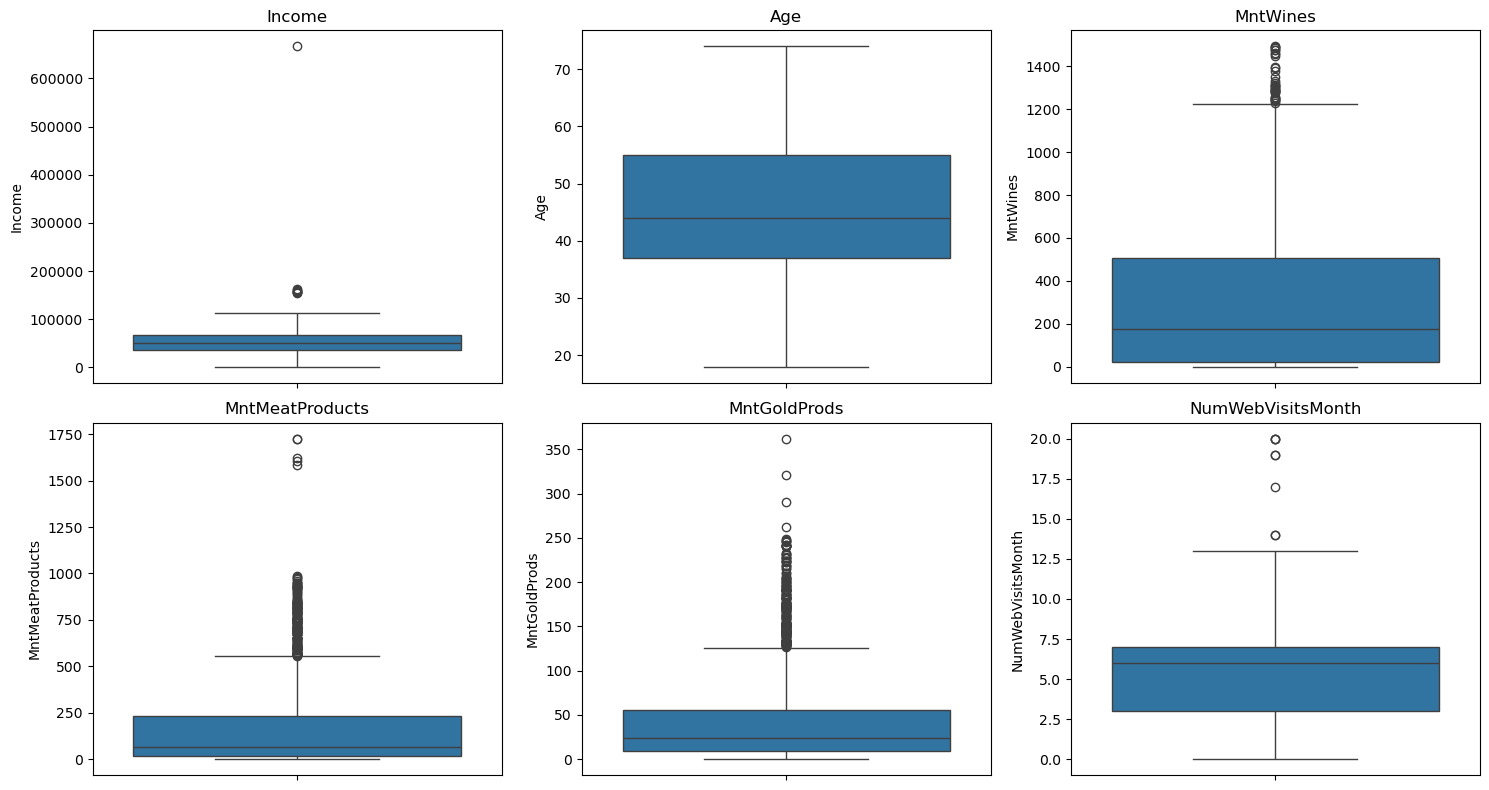

In [26]:
# Boxplots for available numerical columns
outlier_columns = [
    'Income', 'Age', 'MntWines', 'MntMeatProducts',
    'MntGoldProds', 'NumWebVisitsMonth'
]
outlier_columns = [c for c in outlier_columns if c in df.columns and
                   pd.api.types.is_numeric_dtype(df[c])]
if outlier_columns:
    ncols = 3
    nrows = int(np.ceil(len(outlier_columns) / ncols))
    plt.figure(figsize=(15, 4 * nrows))
    for i, col in enumerate(outlier_columns, 1):
        plt.subplot(nrows, ncols, i)
        sns.boxplot(y=df[col])
        plt.title(col)
    plt.tight_layout()
    plt.show()
else:
    print('No selected numerical columns are available for boxplots.')


## Data Preprocessing

 ### Remove unnecessary columns

In [27]:
# Remove identifier and constant columns if they are present

remove_cols = ['ID', 'Z_CostContact', 'Z_Revenue']

removed_cols = [c for c in remove_cols if c in df.columns]

df = df.drop(columns=remove_cols, errors='ignore')

print("Removed columns:", removed_cols)
print("Shape after removing columns:", df.shape)
print("Remaining columns:")
print(df.columns.tolist())


Removed columns: ['ID', 'Z_CostContact', 'Z_Revenue']
Shape after removing columns: (2240, 27)
Remaining columns:
['Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Response', 'Age']


## Feature engineering

In [28]:
# Total spending across product categories
spending_cols = [
    'MntWines', 'MntFruits', 'MntMeatProducts',
    'MntFishProducts', 'MntSweetProducts', 'MntGoldProds'
]
available_spending_cols = [c for c in spending_cols if c in df.columns]
if not available_spending_cols:
    raise KeyError('No product spending columns found. Check the dataset columns.')
df['Total_Spending'] = df[available_spending_cols].sum(axis=1)


In [29]:
# Total purchases across web, catalogue and store channels
purchase_cols = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
available_purchase_cols = [c for c in purchase_cols if c in df.columns]
if not available_purchase_cols:
    raise KeyError('No purchase-channel columns found. Check the dataset columns.')
df['Total_Purchases'] = df[available_purchase_cols].sum(axis=1)


In [30]:
# Total children in the household
child_cols = [c for c in ['Kidhome', 'Teenhome'] if c in df.columns]
if child_cols:
    df['Total_Children'] = df[child_cols].fillna(0).sum(axis=1)
else:
    df['Total_Children'] = 0


In [31]:
# Number of accepted marketing campaigns
campaign_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3',
                 'AcceptedCmp4', 'AcceptedCmp5', 'Response']
available_campaign_cols = [c for c in campaign_cols if c in df.columns]
df['Total_Campaign_Accepted'] = df[available_campaign_cols].fillna(0).sum(axis=1)


In [32]:
# Customer tenure measured in days from the earliest/latest enrollment date
if 'Dt_Customer' not in df.columns:
    raise KeyError("Required column 'Dt_Customer' is missing.")
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], errors='coerce', dayfirst=True)
reference_date = df['Dt_Customer'].max()
if pd.isna(reference_date):
    raise ValueError('Dt_Customer could not be parsed as valid dates.')
df['Customer_Tenure_Days'] = (reference_date - df['Dt_Customer']).dt.days


## Retain original columns for EDA

In [33]:
# Keep original columns for EDA analysis

print("Original product and purchase columns retained.")

print(df.columns.tolist())

Original product and purchase columns retained.
['Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Response', 'Age', 'Total_Spending', 'Total_Purchases', 'Total_Children', 'Total_Campaign_Accepted', 'Customer_Tenure_Days']


## EDA – Data Visualization

### Univariate analysis – Numerical features

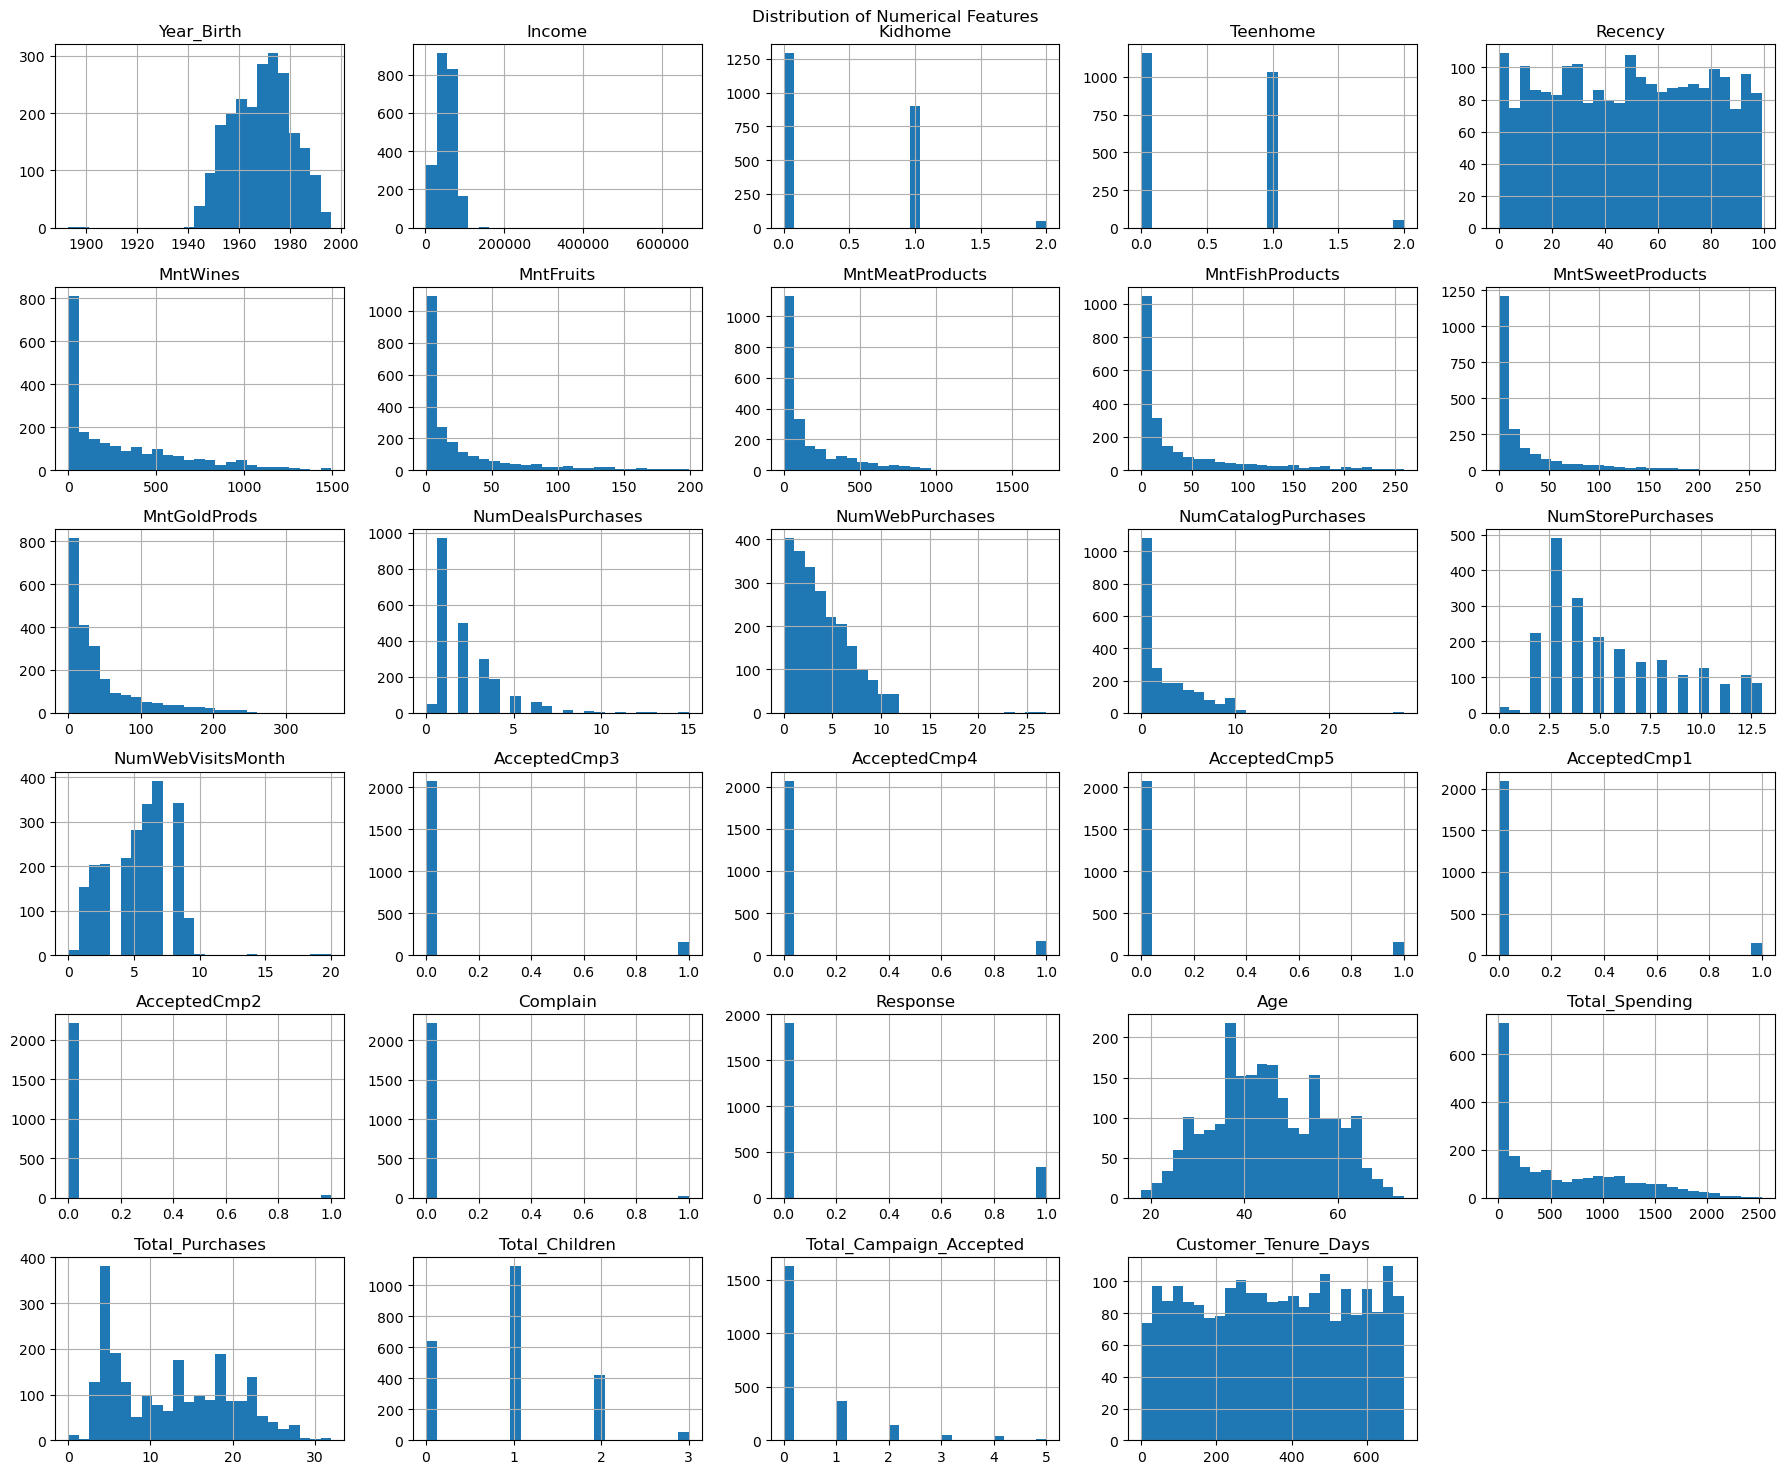

In [34]:
num_cols = df.select_dtypes(
    include=np.number
).columns

df[num_cols].hist(
    figsize=(18,15),
    bins=25
)

plt.suptitle("Distribution of Numerical Features")

plt.tight_layout()
plt.show()

## Categorical analysis

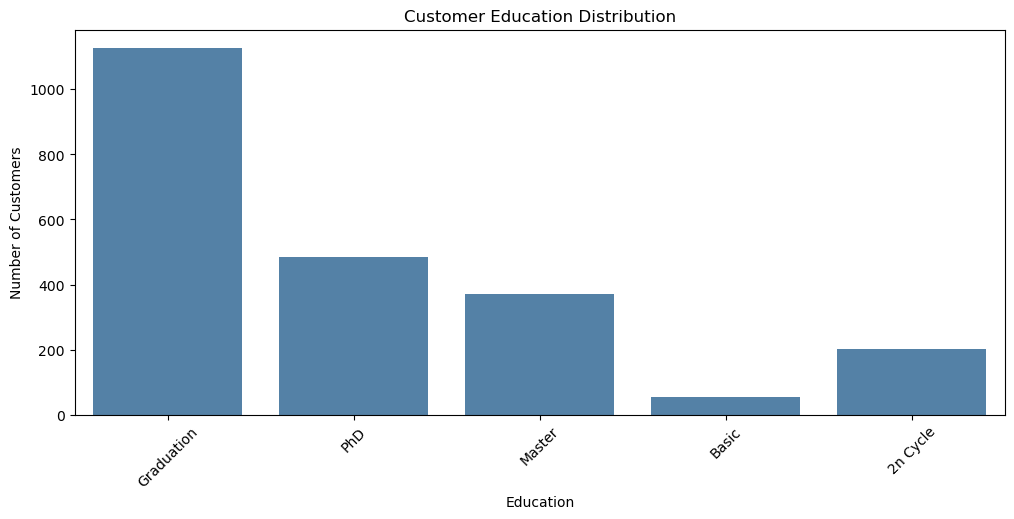

In [35]:
plt.figure(figsize=(12,5))

sns.countplot(
    data=df,
    x='Education',
    color='steelblue'
)

plt.title("Customer Education Distribution")
plt.xlabel("Education")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

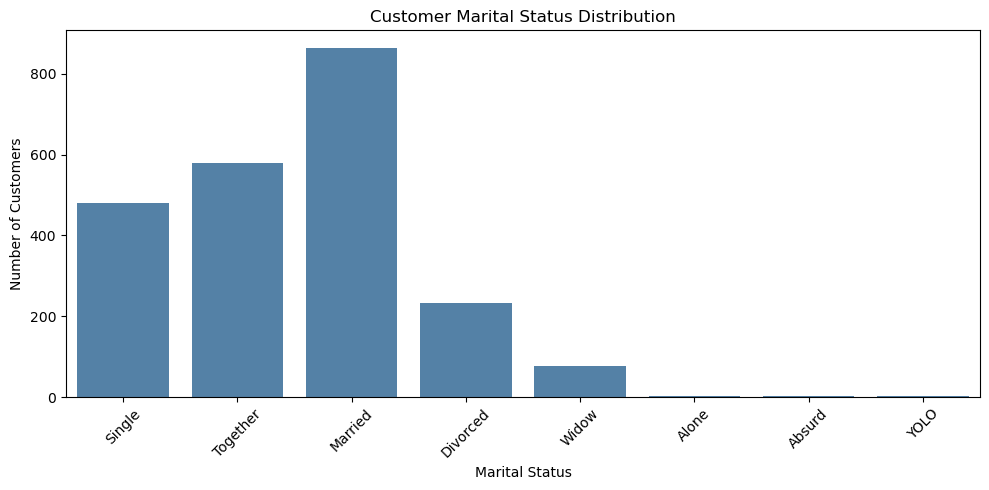

In [36]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x='Marital_Status',
    color='steelblue'
)

plt.title("Customer Marital Status Distribution")
plt.xlabel("Marital Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Spending analysis

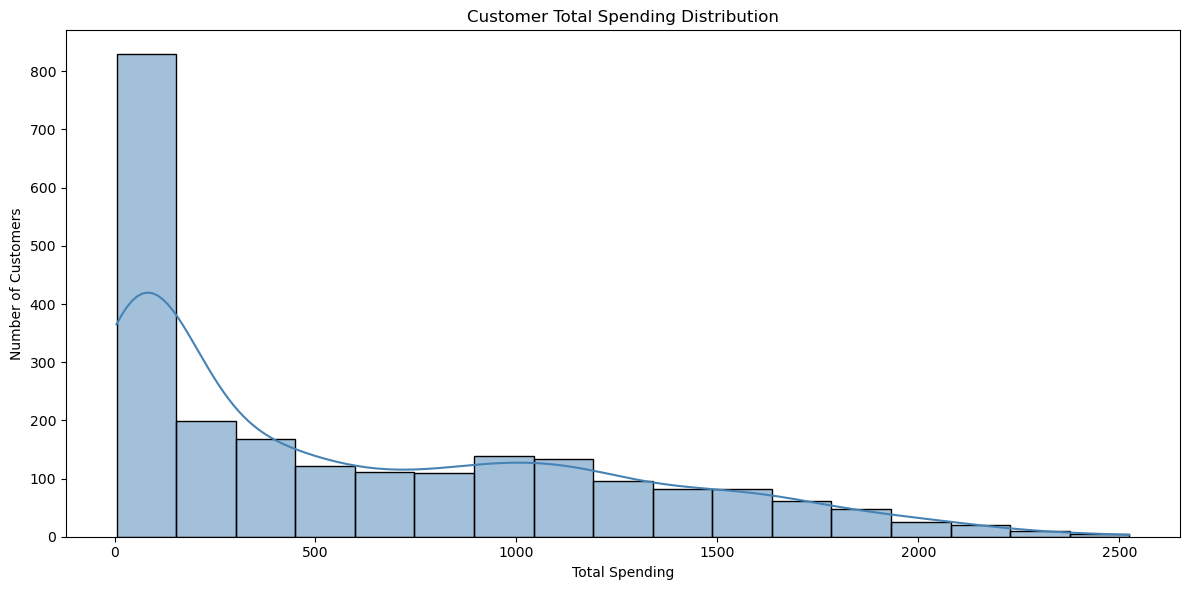

In [37]:
plt.figure(figsize=(12,6))

sns.histplot(
    data=df,
    x='Total_Spending',
    kde=True,
    color='steelblue'
)

plt.title("Customer Total Spending Distribution")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## Spending by education

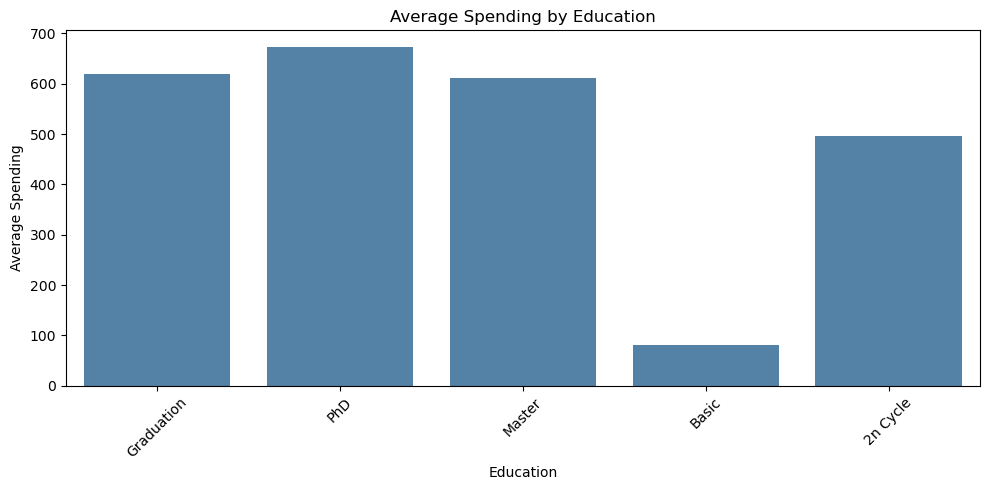

In [38]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x='Education',
    y='Total_Spending',
    errorbar=None,
    color='steelblue'
)

plt.title("Average Spending by Education")
plt.xlabel("Education")
plt.ylabel("Average Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Spending by marital status

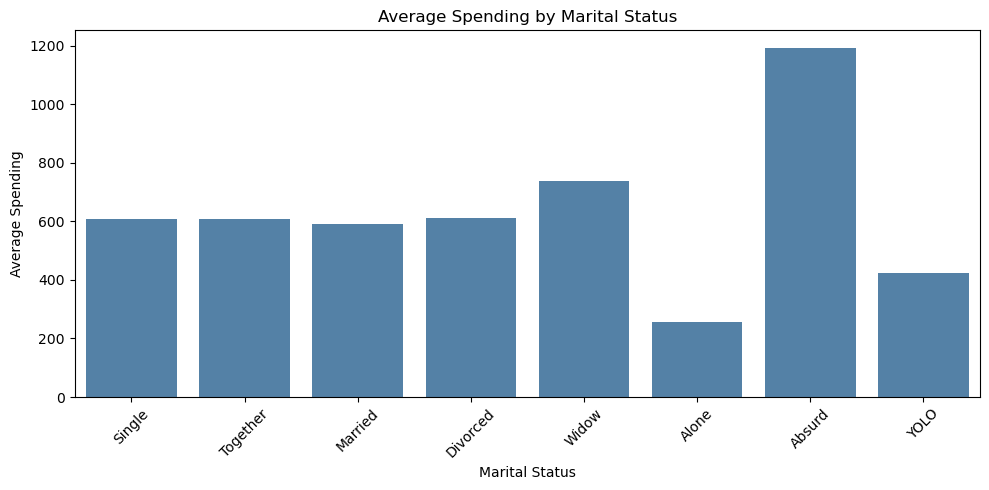

In [39]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x='Marital_Status',
    y='Total_Spending',
    errorbar=None,
    color='steelblue'
)

plt.title("Average Spending by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Average Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Purchase behaviour

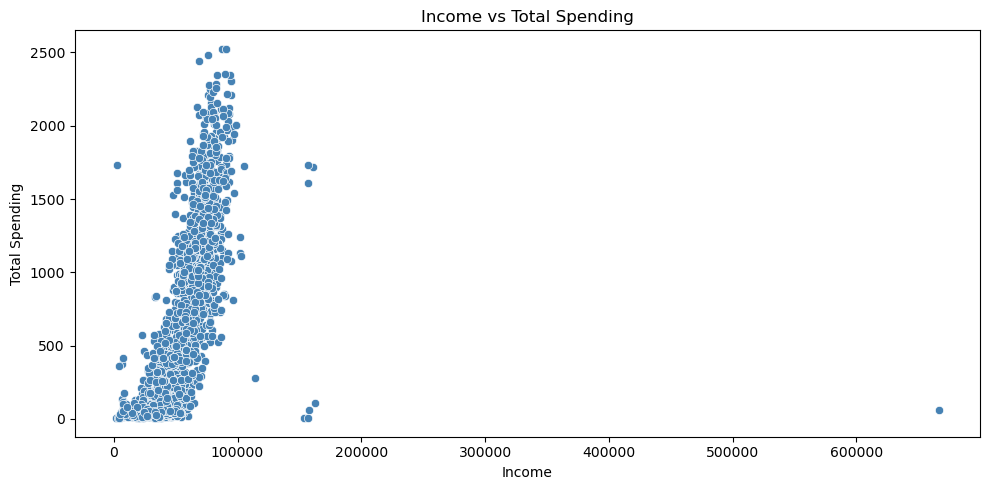

In [40]:
plt.figure(figsize=(10,5))

sns.scatterplot(
    data=df,
    x='Income',
    y='Total_Spending',
    color='steelblue'
)

plt.title("Income vs Total Spending")
plt.xlabel("Income")
plt.ylabel("Total Spending")
plt.tight_layout()
plt.show()

## Recency analysis

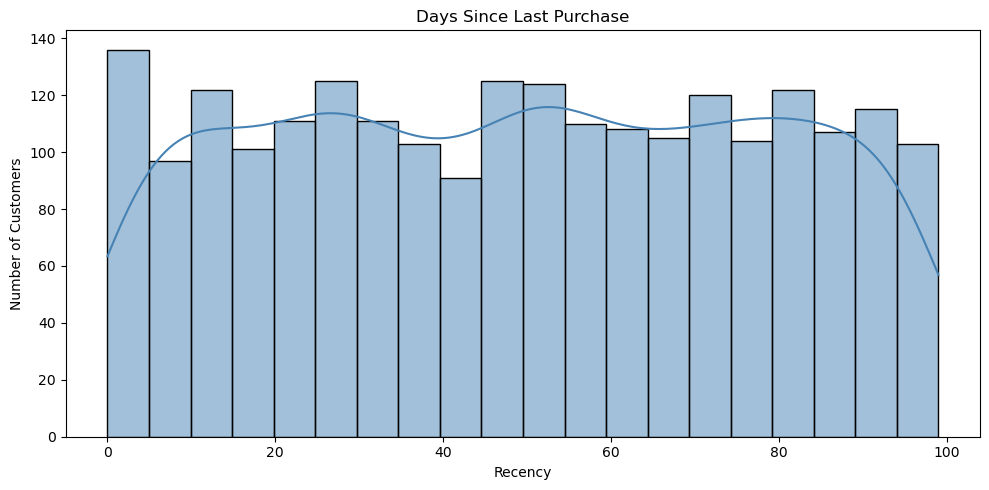

In [41]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='Recency',
    bins=20,
    kde=True,
    color='steelblue'
)

plt.title("Days Since Last Purchase")
plt.xlabel("Recency")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## Correlation heatmap

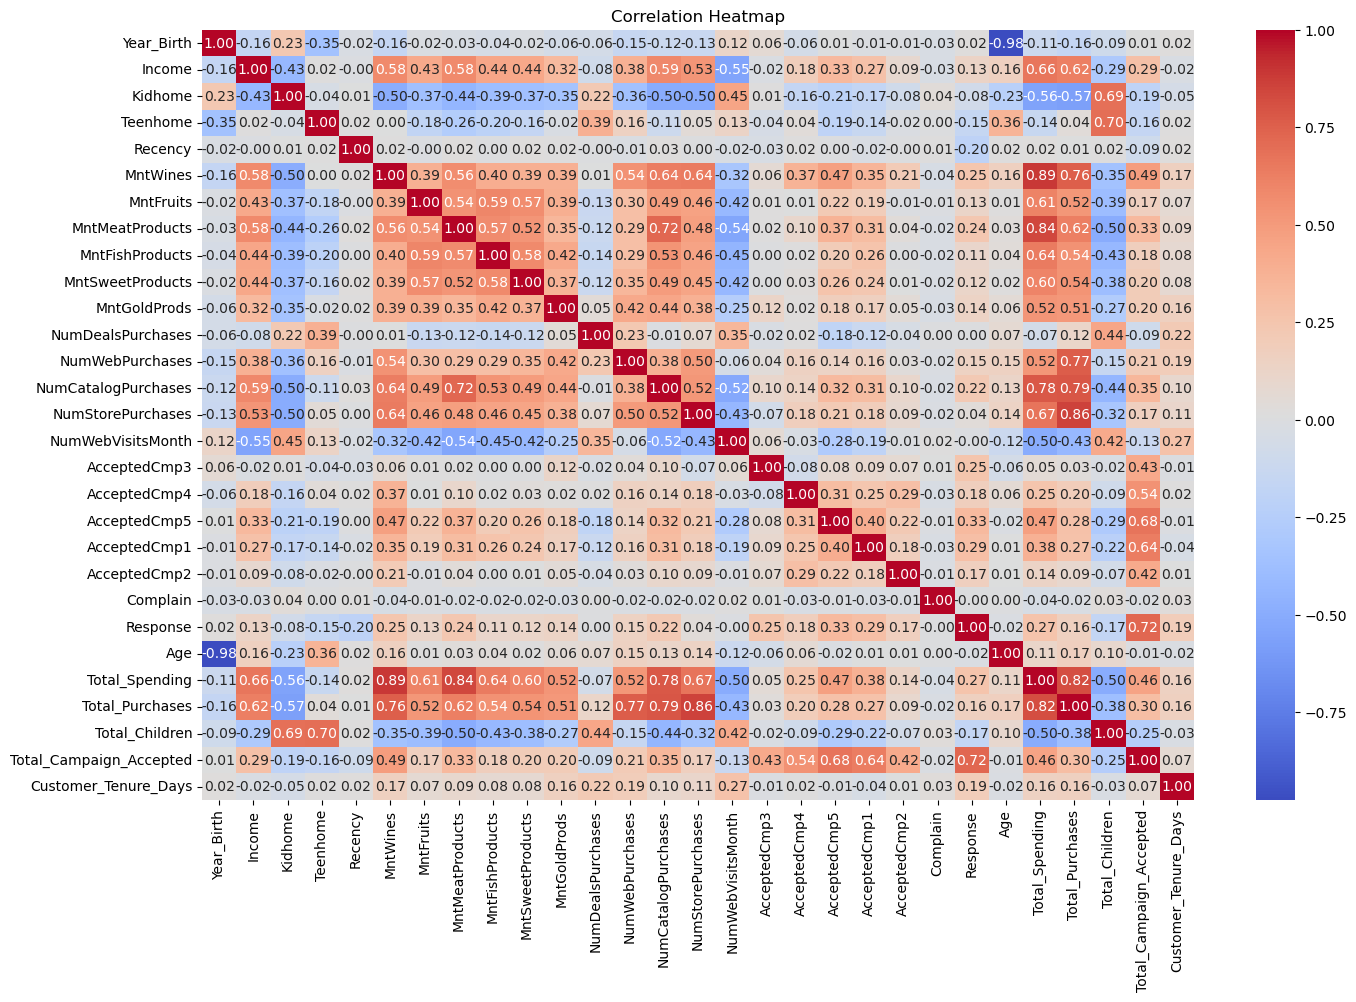

In [42]:
plt.figure(figsize=(16,10))

corr = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

## Pairplot

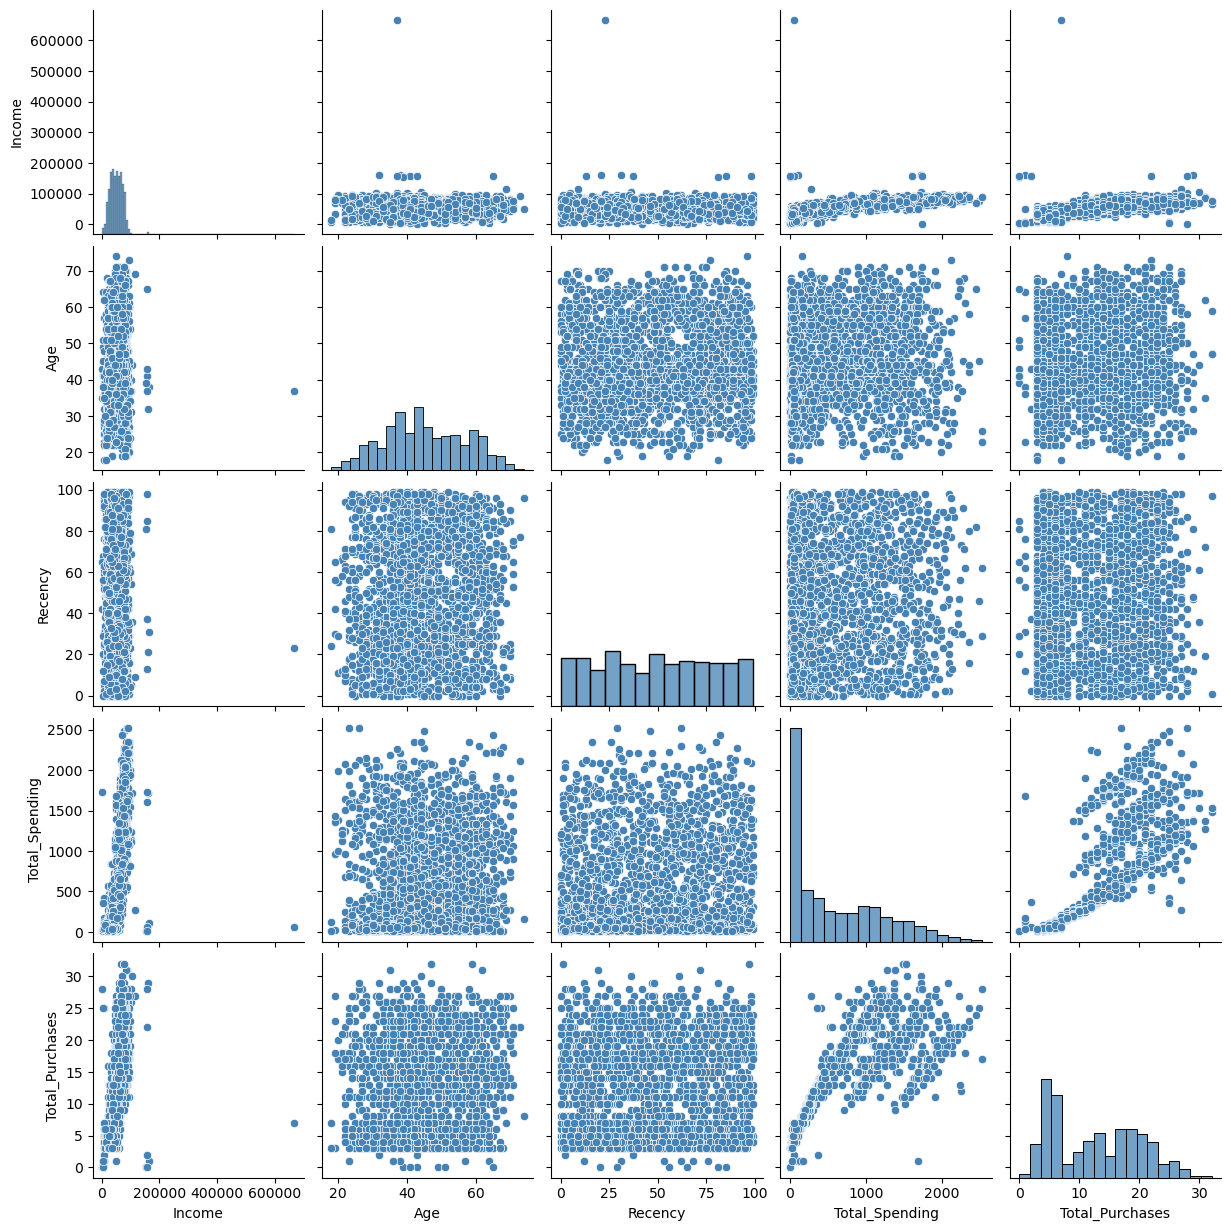

In [43]:
selected_features = [
    'Income',
    'Age',
    'Recency',
    'Total_Spending',
    'Total_Purchases'
]

sns.pairplot(
    df[selected_features],
    diag_kind='hist',
    plot_kws={'color': 'steelblue'},
    diag_kws={'color': 'steelblue'}
)

plt.show()

## IQR capping

In [44]:
# IQR Outlier Capping
# Run this cell AFTER EDA so the EDA charts show the original distributions.

cap_cols = [
    'Income',
    'NumDealsPurchases',
    'NumWebVisitsMonth',
    'MntWines',
    'MntFruits',
    'MntMeatProducts',
    'MntFishProducts',
    'MntSweetProducts',
    'MntGoldProds',
    'NumWebPurchases',
    'NumCatalogPurchases'
]

for col in cap_cols:
    if col not in df.columns:
        continue

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[col] = df[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

# Recalculate engineered totals after capping their source columns
spending_cols = [
    'MntWines', 'MntFruits', 'MntMeatProducts',
    'MntFishProducts', 'MntSweetProducts', 'MntGoldProds'
]
df['Total_Spending'] = df[spending_cols].sum(axis=1)

purchase_cols = [
    'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases'
]
df['Total_Purchases'] = df[purchase_cols].sum(axis=1)

print("IQR outlier capping completed.")
print("Capped columns:", cap_cols)

IQR outlier capping completed.
Capped columns: ['Income', 'NumDealsPurchases', 'NumWebVisitsMonth', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumWebPurchases', 'NumCatalogPurchases']


## Feature Selection

## Select Features for Data Preprocessing

In [45]:
# Feature Selection

features = [
    'Age',
    'Income',
    'Recency',
    'NumDealsPurchases',
    'NumWebVisitsMonth',
    'Total_Spending',
    'Total_Purchases',
    'Total_Children',
    'Total_Campaign_Accepted',
    'Customer_Tenure_Days',
    'Education',
    'Marital_Status'
]

# Check whether all required features are available

missing_features = [
    col for col in features
    if col not in df.columns
]

if missing_features:
    raise KeyError(
        f"Missing features: {missing_features}"
    )

# Create selected feature dataset

X = df[features].copy()

print("Selected Features:")
print(features)

print("\nNumber of Selected Features:", len(features))

print("\nFeature Dataset Shape:", X.shape)

print("\nFirst 5 Rows:")
display(X.head())

print("\nData Types:")
print(X.dtypes)

print("\nMissing Values:")
print(X.isnull().sum())

Selected Features:
['Age', 'Income', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth', 'Total_Spending', 'Total_Purchases', 'Total_Children', 'Total_Campaign_Accepted', 'Customer_Tenure_Days', 'Education', 'Marital_Status']

Number of Selected Features: 12

Feature Dataset Shape: (2240, 12)

First 5 Rows:


,Age,Income,Recency,NumDealsPurchases,NumWebVisitsMonth,Total_Spending,Total_Purchases,Total_Children,Total_Campaign_Accepted,Customer_Tenure_Days,Education,Marital_Status
0,57.0,58138.0,58,3,7,1551.5,22,0,1,663,Graduation,Single
1,60.0,46344.0,38,2,5,27.0,4,2,0,113,Graduation,Single
2,49.0,71613.0,26,1,4,776.0,20,0,0,312,Graduation,Together
3,30.0,26646.0,26,2,6,53.0,6,1,0,139,Graduation,Together
4,33.0,58293.0,94,5,5,422.0,14,1,0,161,PhD,Married



Data Types:
Age                        float64
Income                     float64
Recency                      int64
NumDealsPurchases            int64
NumWebVisitsMonth            int64
Total_Spending             float64
Total_Purchases              int64
Total_Children               int64
Total_Campaign_Accepted      int64
Customer_Tenure_Days         int64
Education                   object
Marital_Status              object
dtype: object

Missing Values:
Age                        0
Income                     0
Recency                    0
NumDealsPurchases          0
NumWebVisitsMonth          0
Total_Spending             0
Total_Purchases            0
Total_Children             0
Total_Campaign_Accepted    0
Customer_Tenure_Days       0
Education                  0
Marital_Status             0
dtype: int64


## Identify highly correlated features


In [46]:
corr_matrix = df.select_dtypes(
    include=np.number
).corr().abs()

upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_features = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > 0.85)
]

print("Highly correlated features:")
print(high_corr_features)

Highly correlated features:
['Age', 'Total_Spending', 'Total_Purchases']


## Encoding – Categorical data conversion

In [47]:
# Identify categorical and numerical columns

# These columns are categorical even if stored as numbers
categorical_cols = [
    col for col in ['Education', 'Marital_Status']
    if col in X.columns
]

# Remaining columns are numerical
numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numerical_cols)

Categorical Columns: ['Education', 'Marital_Status']
Numerical Columns: ['Age', 'Income', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth', 'Total_Spending', 'Total_Purchases', 'Total_Children', 'Total_Campaign_Accepted', 'Customer_Tenure_Days']


## Feature Scaling

## Final Preprocessing Pipeline

In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Re-identify column types directly from X to avoid stale column lists
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = [c for c in X.columns if c not in categorical_cols]

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

transformers = []
if numerical_cols:
    transformers.append(('num', numeric_pipeline, numerical_cols))
if categorical_cols:
    transformers.append(('cat', categorical_pipeline, categorical_cols))
if not transformers:
    raise ValueError('No usable features found in X.')

preprocessor = ColumnTransformer(transformers=transformers)
X_processed = preprocessor.fit_transform(X)
print('Original shape:', X.shape)
print('Processed shape:', X_processed.shape)
print('Preprocessing completed successfully.')


Original shape: (2240, 12)
Processed shape: (2240, 23)
Preprocessing completed successfully.


## Final data validation

### Check missing values

In [49]:
print("Missing values in selected features:")
print(X.isnull().sum())

print("\nProcessed data shape:")
print(X_processed.shape)

# Check that the transformed numeric data contains no NaN or infinite values
if hasattr(X_processed, "data"):  # Sparse matrix
    processed_values = X_processed.data
else:
    processed_values = np.asarray(X_processed)

print("\nProcessed data contains only finite values:",
      np.isfinite(processed_values).all())

Missing values in selected features:
Age                        0
Income                     0
Recency                    0
NumDealsPurchases          0
NumWebVisitsMonth          0
Total_Spending             0
Total_Purchases            0
Total_Children             0
Total_Campaign_Accepted    0
Customer_Tenure_Days       0
Education                  0
Marital_Status             0
dtype: int64

Processed data shape:
(2240, 23)

Processed data contains only finite values: True


## Check final data

In [50]:
print("Original Dataset Shape:", df.shape)

print("Selected Features Shape:", X.shape)

print("Processed Data Shape:", X_processed.shape)

print("Processed Data Type:", type(X_processed))

print("Data Preprocessing Completed Successfully")

Original Dataset Shape: (2240, 32)
Selected Features Shape: (2240, 12)
Processed Data Shape: (2240, 23)
Processed Data Type: <class 'numpy.ndarray'>
Data Preprocessing Completed Successfully


## Final EDA summary

In [51]:
print("CUSTOMER PERSONALITY ANALYSIS")
print("--------------------------------")

print("Total Customers:", len(df))
print("Total Features after cleaning and feature engineering:", df.shape[1])
print("Remaining Missing Values:", df.isnull().sum().sum())
print("Remaining Exact Duplicate Records:", remaining_duplicate_rows)
print("Average Income:", round(df['Income'].mean(), 2))
print("Average Total Spending:", round(df['Total_Spending'].mean(), 2))
print("Average Recency:", round(df['Recency'].mean(), 2))

print("\nEDA, Data Cleaning, and Data Preprocessing Completed.")

CUSTOMER PERSONALITY ANALYSIS
--------------------------------
Total Customers: 2240
Total Features after cleaning and feature engineering: 32
Remaining Missing Values: 0
Remaining Exact Duplicate Records: 0
Average Income: 51865.87
Average Total Spending: 568.21
Average Recency: 49.11

EDA, Data Cleaning, and Data Preprocessing Completed.


# Model Building & Model Evaluation
**Project target:** perform clustering to summarise customer segments.

The steps below continue from the preprocessed data above. Three small data fixes come first, because they change which customers and features go into the clustering model.

## Pre-modelling fix 1: Remove duplicate customers
The earlier duplicate check compared every column including `ID`, so it found nothing. `ID` has since been dropped, so rows that are identical in every other column can now be detected. These are the same customer entered twice under different IDs, and keeping them would give those customers double weight in the clustering.

In [52]:
print("Rows before:", len(df))
print("Duplicate customers (identical in every column except ID):", df.duplicated().sum())

df = df.drop_duplicates().copy()
print("Rows after removing duplicates:", len(df))

Rows before: 2240
Duplicate customers (identical in every column except ID): 182
Rows after removing duplicates: 2058


## Pre-modelling fix 2: Clean the categorical columns
- `Marital_Status` has junk values (`Absurd`, `YOLO`) and an `Alone` category with only 3 customers. For segmentation, what matters is whether the customer lives with a partner, so it is grouped into **Partner** / **Alone**.
- `Education` is grouped into three ordered levels: **Basic = 0**, **Graduate = 1** (`2n Cycle`, `Graduation`), **Postgraduate = 2** (`Master`, `PhD`).

Both become numeric columns. One-hot encoding them (as in the earlier pipeline) would add 13 extra 0/1 columns that would dominate the distance calculations in K-Means and push the clusters to split on marital status.

In [53]:
df['Living_With'] = df['Marital_Status'].replace({
    'Married': 'Partner', 'Together': 'Partner',
    'Single': 'Alone', 'Divorced': 'Alone', 'Widow': 'Alone',
    'Alone': 'Alone', 'Absurd': 'Alone', 'YOLO': 'Alone'
})
df['Is_Partner'] = (df['Living_With'] == 'Partner').astype(int)

df['Education_Level'] = df['Education'].map({
    'Basic': 0, '2n Cycle': 1, 'Graduation': 1, 'Master': 2, 'PhD': 2
})

print(df['Living_With'].value_counts())
print()
print(df['Education_Level'].value_counts().sort_index())
print("\nMissing Education_Level values:", df['Education_Level'].isna().sum())

Living_With
Partner    1316
Alone       742
Name: count, dtype: int64

Education_Level
0      49
1    1218
2     791
Name: count, dtype: int64

Missing Education_Level values: 0


## Pre-modelling fix 3: Final modelling features and scaling
The same 12 features selected earlier are used, with `Education` and `Marital_Status` replaced by the two numeric columns created above. All features are standardised (mean 0, standard deviation 1) so that large-valued columns such as `Income` do not outweigh small ones such as `Total_Children`.

In [54]:
from sklearn.preprocessing import StandardScaler

model_features = [
    'Age', 'Income', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth',
    'Total_Spending', 'Total_Purchases', 'Total_Children',
    'Total_Campaign_Accepted', 'Customer_Tenure_Days',
    'Education_Level', 'Is_Partner'
]

X_model = df[model_features].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_model)

print("Modelling data shape:", X_scaled.shape)
print("Means after scaling (should be ~0):", X_scaled.mean(axis=0).round(2))
print("Std after scaling   (should be 1): ", X_scaled.std(axis=0).round(2))

Modelling data shape: (2058, 12)
Means after scaling (should be ~0): [-0. -0. -0. -0. -0. -0. -0. -0.  0.  0.  0. -0.]
Std after scaling   (should be 1):  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Model Building Step 1: Dimensionality reduction with PCA
Several features are strongly correlated (for example `Income`, `Total_Spending` and `Total_Purchases`). PCA combines them into uncorrelated components, which removes redundant information and some noise before clustering. Enough components are kept to explain at least 80% of the variance.

Component  Explained_Variance_%  Cumulative_%
      PC1                 29.78         29.78
      PC2                 13.58         43.36
      PC3                 10.99         54.35
      PC4                  8.78         63.14
      PC5                  8.38         71.52
      PC6                  7.20         78.71
      PC7                  6.57         85.28
      PC8                  6.00         91.28
      PC9                  3.75         95.04
     PC10                  2.68         97.72
     PC11                  1.23         98.95
     PC12                  1.05        100.00

Components needed for >= 80% variance: 7 (85.3% explained)


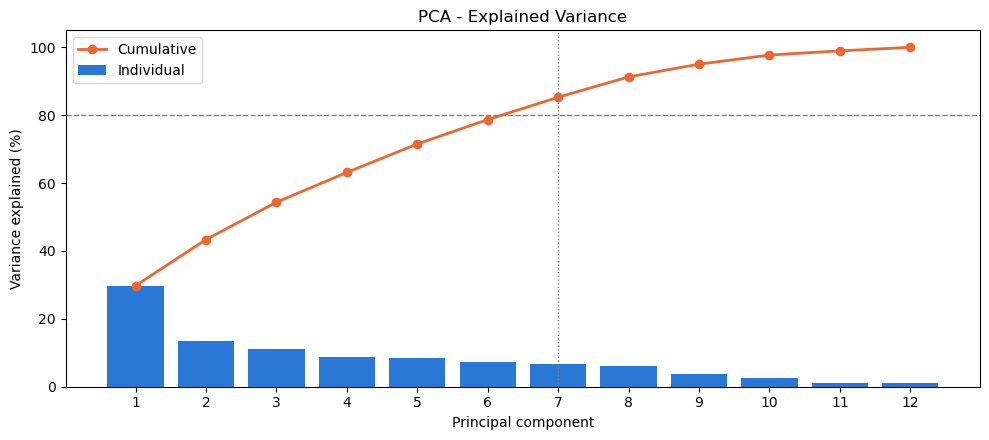

In [55]:
from sklearn.decomposition import PCA

pca_full = PCA(random_state=42).fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

pca_table = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(len(explained))],
    'Explained_Variance_%': (explained * 100).round(2),
    'Cumulative_%': (cumulative * 100).round(2)
})
print(pca_table.to_string(index=False))

n_components = int(np.argmax(cumulative >= 0.80) + 1)
print(f"\nComponents needed for >= 80% variance: {n_components} "
      f"({cumulative[n_components-1]*100:.1f}% explained)")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(1, len(explained) + 1), explained * 100, color='#2a78d6', label='Individual')
ax.plot(range(1, len(explained) + 1), cumulative * 100, color='#eb6834', marker='o', linewidth=2, label='Cumulative')
ax.axhline(80, color='gray', linestyle='--', linewidth=1)
ax.axvline(n_components, color='gray', linestyle=':', linewidth=1)
ax.set_xlabel('Principal component')
ax.set_ylabel('Variance explained (%)')
ax.set_title('PCA - Explained Variance')
ax.set_xticks(range(1, len(explained) + 1))
ax.legend()
plt.tight_layout()
plt.show()

In [56]:
pca = PCA(n_components=n_components, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("Data shape after PCA:", X_pca.shape)

# What the first two components represent
loadings = pd.DataFrame(pca.components_[:2].T, index=model_features, columns=['PC1', 'PC2']).round(2)
print("\nLoadings of the first two components:")
print(loadings.sort_values('PC1', ascending=False))

Data shape after PCA: (2058, 7)

Loadings of the first two components:
                          PC1   PC2
Total_Spending           0.48  0.18
Income                   0.47  0.07
Total_Purchases          0.44  0.29
Total_Campaign_Accepted  0.26  0.07
Age                      0.10  0.23
Education_Level          0.08  0.14
Customer_Tenure_Days     0.01  0.47
Recency                 -0.01  0.04
Is_Partner              -0.02  0.02
NumDealsPurchases       -0.15  0.62
Total_Children          -0.33  0.31
NumWebVisitsMonth       -0.37  0.31


## Model Building Step 2: Choosing the number of clusters
K-Means is run for k = 2 to 10 and four measures are compared:
- **Inertia (elbow method):** total within-cluster distance. Look for the point where it stops dropping sharply.
- **Silhouette score:** how well each customer fits its own cluster compared with the nearest other cluster (-1 to 1, higher is better).
- **Davies-Bouldin index:** average similarity between each cluster and its closest neighbour (lower is better).
- **Calinski-Harabasz index:** ratio of between-cluster to within-cluster spread (higher is better).

 k  Inertia  Silhouette  Davies_Bouldin  Calinski_Harabasz  Smallest_cluster
 2  15413.4       0.246           1.590              753.4               843
 3  13414.4       0.199           1.743              585.7               555
 4  12361.5       0.169           1.821              481.9               463
 5  11465.2       0.152           1.911              429.6               231
 6  10878.8       0.148           1.837              384.1               220
 7  10348.2       0.145           1.888              353.9               182
 8   9945.0       0.148           1.849              327.3               181
 9   9589.2       0.148           1.831              306.4               145
10   9273.9       0.140           1.888              289.2               147


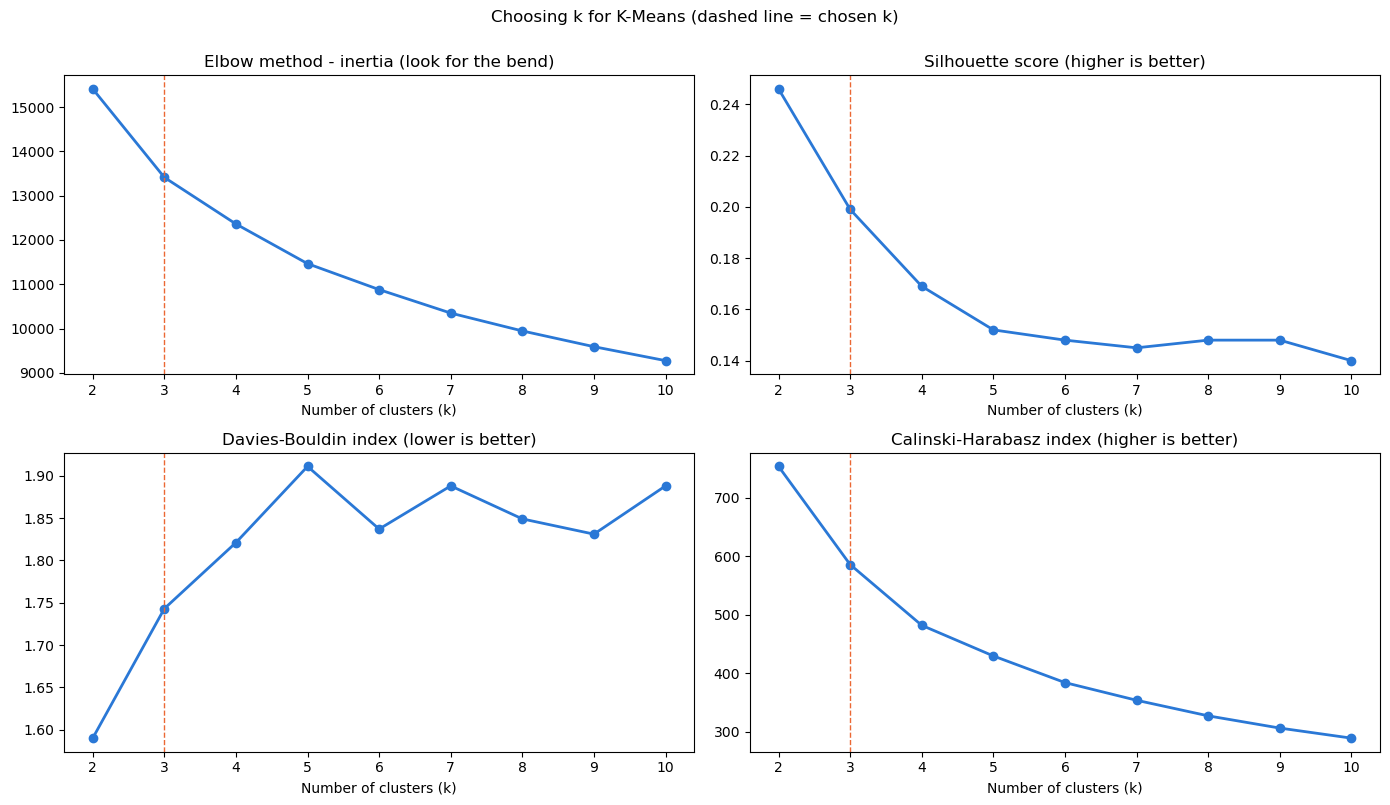

In [57]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

k_range = range(2, 11)
k_scores = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_pca)
    k_scores.append({
        'k': k,
        'Inertia': round(km.inertia_, 1),
        'Silhouette': round(silhouette_score(X_pca, km.labels_), 3),
        'Davies_Bouldin': round(davies_bouldin_score(X_pca, km.labels_), 3),
        'Calinski_Harabasz': round(calinski_harabasz_score(X_pca, km.labels_), 1),
        'Smallest_cluster': int(np.bincount(km.labels_).min())
    })
k_scores = pd.DataFrame(k_scores)
print(k_scores.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
plots = [('Inertia', 'Elbow method - inertia (look for the bend)'),
         ('Silhouette', 'Silhouette score (higher is better)'),
         ('Davies_Bouldin', 'Davies-Bouldin index (lower is better)'),
         ('Calinski_Harabasz', 'Calinski-Harabasz index (higher is better)')]
for ax, (col, title) in zip(axes.ravel(), plots):
    ax.plot(k_scores['k'], k_scores[col], marker='o', color='#2a78d6', linewidth=2)
    ax.axvline(3, color='#eb6834', linestyle='--', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel('Number of clusters (k)')
    ax.set_xticks(list(k_range))
plt.suptitle('Choosing k for K-Means (dashed line = chosen k)', y=1.0)
plt.tight_layout()
plt.show()

**Why k = 3**
- **Elbow:** there is no sharp elbow. Inertia drops by about 2,000 from k = 2 to 3, by about 1,050 from 3 to 4, and then flattens out gradually.
- **k = 2** scores best on all three quality measures, but it only splits customers into high spenders and low spenders. That is too coarse to guide marketing.
- **k = 3** is second best on silhouette (0.199), Davies-Bouldin (1.743) and Calinski-Harabasz (585.7), and every cluster is a usable size (smallest is 555 customers, 27%).
- **From k = 4 onwards** all three measures keep getting worse.

*About the score level:* a silhouette around 0.2 is normal for customer data. Customers vary continuously rather than forming tightly separated groups, so the segments are real but have soft boundaries.

In [58]:
# Stability check: does K-Means find the same clusters on different random samples of customers?
from sklearn.metrics import adjusted_rand_score

rng = np.random.RandomState(42)
stability = {}
for k in [2, 3, 4, 5]:
    base = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_pca)
    aris = []
    for _ in range(20):
        idx = rng.choice(len(X_pca), size=len(X_pca), replace=True)
        boot = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_pca[idx])
        # compare the bootstrap model's labels with the full model's labels on all customers
        aris.append(adjusted_rand_score(base.labels_, boot.predict(X_pca)))
    stability[k] = (round(np.mean(aris), 3), round(np.min(aris), 3))

stab_df = pd.DataFrame(stability, index=['Mean ARI', 'Worst ARI']).T
stab_df.index.name = 'k'
print("Bootstrap stability (Adjusted Rand Index, 1 = identical clusters every time):")
print(stab_df)

Bootstrap stability (Adjusted Rand Index, 1 = identical clusters every time):
   Mean ARI  Worst ARI
k                     
2     0.971      0.911
3     0.946      0.889
4     0.849      0.521
5     0.879      0.825


**k = 3 is stable.** Across 20 bootstrap resamples, K-Means with k = 3 found almost the same clusters as on the full data (mean ARI 0.946, worst 0.889). With k = 4 the result depends much more on which customers are sampled (mean 0.849, worst 0.521), which means the 4th cluster is not a reliable segment. This supports k = 3.

## Model Building Step 3: K-Means (k = 3)

In [59]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=20, random_state=42)
raw_labels = kmeans.fit_predict(X_pca)

# K-Means numbers its clusters arbitrarily, so the numbering can change between library versions.
# Re-order the centroids by average income so that Cluster 0 = lowest income ... Cluster 2 = highest income.
order = df['Income'].groupby(raw_labels).mean().sort_values().index.to_numpy()
kmeans.cluster_centers_ = kmeans.cluster_centers_[order]
km_labels = kmeans.predict(X_pca)

print("Average income per cluster:", df['Income'].groupby(km_labels).mean().round(0).to_dict())
print("\nK-Means cluster sizes:")
print(pd.Series(km_labels).value_counts().sort_index())

Average income per cluster: {0: 34391.0, 1: 55591.0, 2: 75046.0}

K-Means cluster sizes:
0    904
1    555
2    599
Name: count, dtype: int64


## Model Building Step 4: Agglomerative (hierarchical) clustering
Ward linkage merges customers bottom-up, each time joining the two groups whose merger increases the within-group variance the least. The dendrogram shows how the groups merge, and cutting it into 3 branches gives the clusters.

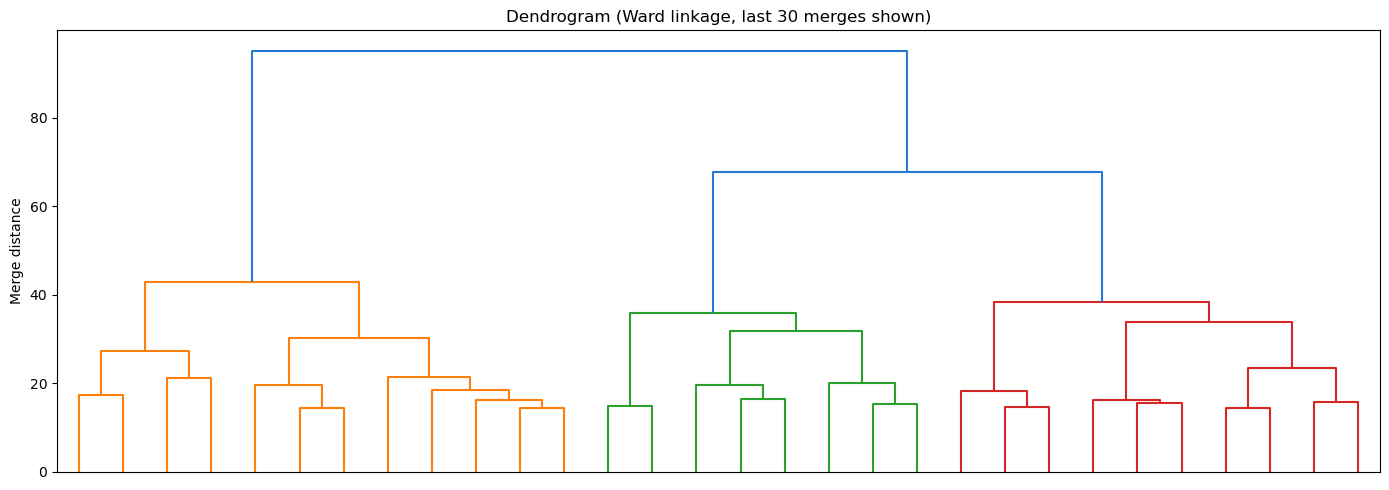

Agglomerative cluster sizes:
0    910
1    631
2    517
Name: count, dtype: int64


In [60]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

linkage_matrix = linkage(X_pca, method='ward')
plt.figure(figsize=(14, 5))
dendrogram(linkage_matrix, truncate_mode='lastp', p=30, color_threshold=None,
           above_threshold_color='#2a78d6', no_labels=True)
plt.title('Dendrogram (Ward linkage, last 30 merges shown)')
plt.ylabel('Merge distance')
plt.tight_layout()
plt.show()

agg = AgglomerativeClustering(n_clusters=K, linkage='ward')
agg_labels = agg.fit_predict(X_pca)
print("Agglomerative cluster sizes:")
print(pd.Series(agg_labels).value_counts().sort_index())

## Model Building Step 5: Gaussian Mixture Model (GMM)
A GMM assumes each segment is an elliptical cloud and gives each customer a probability of belonging to each cluster (soft clustering). The BIC (Bayesian Information Criterion, lower is better) is checked for different numbers of components.

BIC by number of components: {1: 44673.9, 2: 43643.2, 3: 42716.8, 4: 42795.3, 5: 37234.6, 6: 37062.3, 7: 37401.4, 8: 36044.0}


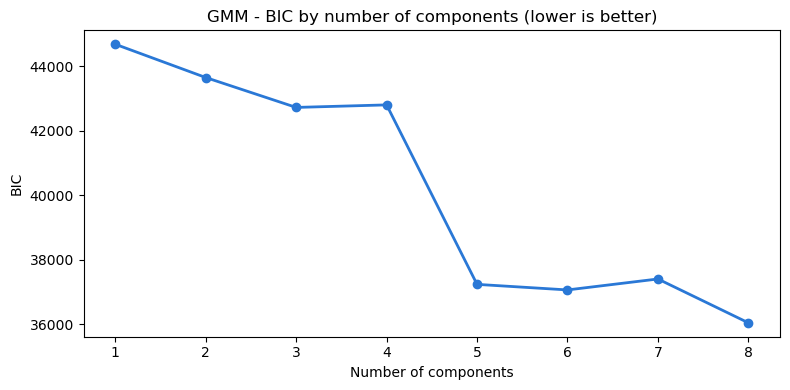

GMM cluster sizes:
0    723
1    392
2    943
Name: count, dtype: int64

Customers assigned with >= 90% probability: 79.3%


In [61]:
from sklearn.mixture import GaussianMixture

bic = []
for k in range(1, 9):
    g = GaussianMixture(n_components=k, n_init=5, random_state=42).fit(X_pca)
    bic.append(g.bic(X_pca))
print("BIC by number of components:", {k: round(float(b), 1) for k, b in zip(range(1, 9), bic)})

plt.figure(figsize=(8, 4))
plt.plot(range(1, 9), bic, marker='o', color='#2a78d6', linewidth=2)
plt.title('GMM - BIC by number of components (lower is better)')
plt.xlabel('Number of components')
plt.ylabel('BIC')
plt.tight_layout()
plt.show()

gmm = GaussianMixture(n_components=K, n_init=5, random_state=42).fit(X_pca)
gmm_labels = gmm.predict(X_pca)
gmm_confidence = gmm.predict_proba(X_pca).max(axis=1)
print("GMM cluster sizes:")
print(pd.Series(gmm_labels).value_counts().sort_index())
print(f"\nCustomers assigned with >= 90% probability: {(gmm_confidence >= 0.9).mean()*100:.1f}%")

**GMM result:** BIC keeps falling as components are added, with a large drop at 5 components (44,674 at 1 component, 36,044 at 8). This is most likely the GMM fitting separate narrow components to the discrete columns (`Is_Partner`, `Education_Level`, number of children), not finding more real segments, so BIC is not a reliable guide to k here. Among 1-4 components BIC is lowest at 3, which matches the K-Means choice, so the GMM is compared at k = 3. About 79% of customers are assigned to a cluster with at least 90% probability.

# Model Evaluation
## Evaluation 1: Compare the three models
Clustering has no correct answer to check against, so the models are compared on internal quality scores. The silhouette score is also calculated on the full 12 scaled features, not only on the PCA components, to make sure the clusters are not an artefact of the PCA step.

                      Silhouette (PCA space)  Silhouette (all 12 features)  Davies_Bouldin  Calinski_Harabasz    Cluster sizes
Model                                                                                                                         
K-Means                                0.199                         0.169           1.743              585.7  [904, 599, 555]
Agglomerative (Ward)                   0.160                         0.136           1.969              490.6  [910, 631, 517]
Gaussian Mixture                       0.155                         0.133           1.921              483.2  [943, 723, 392]


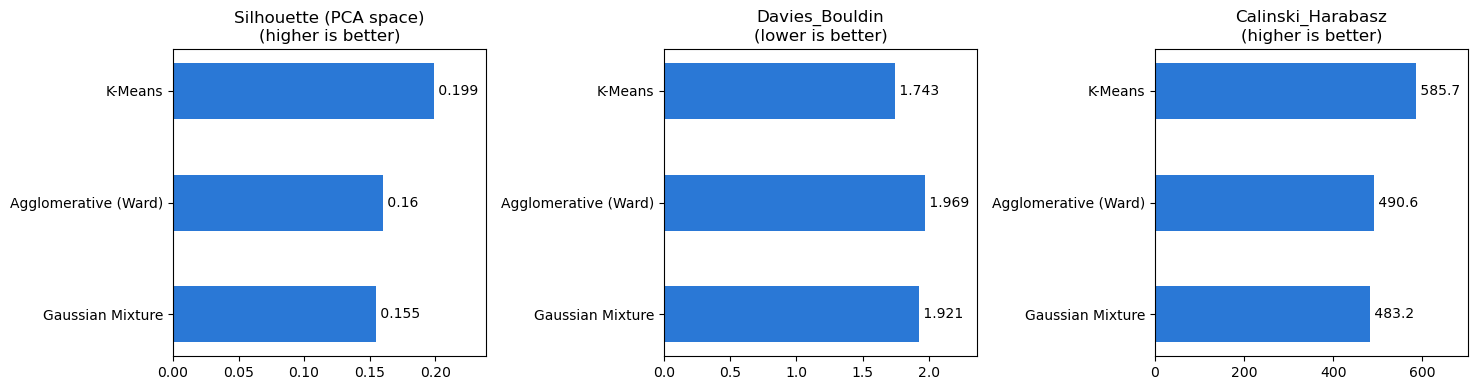

In [62]:
models = {'K-Means': km_labels, 'Agglomerative (Ward)': agg_labels, 'Gaussian Mixture': gmm_labels}

eval_rows = []
for name, labels in models.items():
    eval_rows.append({
        'Model': name,
        'Silhouette (PCA space)': round(silhouette_score(X_pca, labels), 3),
        'Silhouette (all 12 features)': round(silhouette_score(X_scaled, labels), 3),
        'Davies_Bouldin': round(davies_bouldin_score(X_pca, labels), 3),
        'Calinski_Harabasz': round(calinski_harabasz_score(X_pca, labels), 1),
        'Cluster sizes': sorted(np.bincount(labels).tolist(), reverse=True)
    })
eval_df = pd.DataFrame(eval_rows).set_index('Model')
print(eval_df.to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, better in zip(axes, ['Silhouette (PCA space)', 'Davies_Bouldin', 'Calinski_Harabasz'],
                           ['higher is better', 'lower is better', 'higher is better']):
    ax.barh(eval_df.index, eval_df[col], color='#2a78d6', height=0.5)
    ax.set_title(f'{col}\n({better})')
    ax.invert_yaxis()
    ax.set_xlim(0, eval_df[col].max() * 1.2)
    for i, v in enumerate(eval_df[col]):
        ax.text(v, i, f' {v}', va='center')
plt.tight_layout()
plt.show()

In [63]:
# How much do the three models agree with each other? (Adjusted Rand Index)
names = list(models)
agree = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        agree.loc[a, b] = round(adjusted_rand_score(models[a], models[b]), 3)
print("Agreement between models (ARI, 1 = identical clusters):")
print(agree)

Agreement between models (ARI, 1 = identical clusters):
                      K-Means  Agglomerative (Ward)  Gaussian Mixture
K-Means                 1.000                 0.615             0.521
Agglomerative (Ward)    0.615                 1.000             0.530
Gaussian Mixture        0.521                 0.530             1.000


**Result: K-Means is the best model.**
- K-Means scores best on every measure: highest silhouette (0.199 on the PCA components, 0.169 on all 12 features), lowest Davies-Bouldin (1.743) and highest Calinski-Harabasz (585.7).
- The silhouette on all 12 original features is only slightly lower than on the PCA components, so the clusters are not an artefact of the PCA step.
- Agglomerative clustering, a completely different algorithm, finds similar groups (ARI 0.615 with K-Means, and similar cluster sizes: 910/631/517 vs 904/599/555). This confirms the three-segment structure. The GMM agrees less (ARI 0.521).
- K-Means is also the easiest to explain and deploy: a new customer is assigned to the nearest cluster centre.

**Final model: K-Means, k = 3, on 7 principal components.**

## Evaluation 2: Visualise the final clusters
The clusters are plotted on the first two principal components. Clear separation in this 2-D view suggests the segments are genuinely different groups of customers.

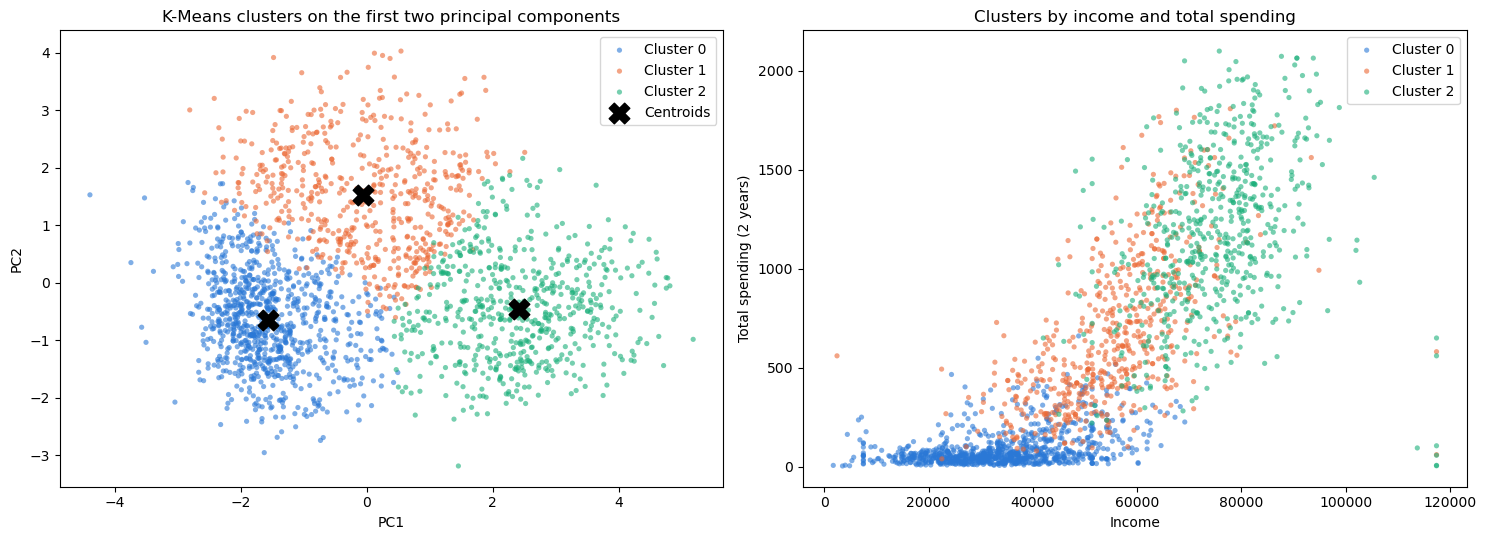

In [64]:
df['Cluster'] = km_labels
cluster_colors = ['#2a78d6', '#eb6834', '#1baf7a']

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for c in range(K):
    mask = km_labels == c
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], s=14, alpha=0.6,
                    color=cluster_colors[c], label=f'Cluster {c}', edgecolors='none')
centers = kmeans.cluster_centers_
axes[0].scatter(centers[:, 0], centers[:, 1], s=220, c='black', marker='X', label='Centroids')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].set_title('K-Means clusters on the first two principal components')
axes[0].legend()

for c in range(K):
    mask = df['Cluster'] == c
    axes[1].scatter(df.loc[mask, 'Income'], df.loc[mask, 'Total_Spending'], s=14, alpha=0.6,
                    color=cluster_colors[c], label=f'Cluster {c}', edgecolors='none')
axes[1].set_xlabel('Income')
axes[1].set_ylabel('Total spending (2 years)')
axes[1].set_title('Clusters by income and total spending')
axes[1].legend()
plt.tight_layout()
plt.show()

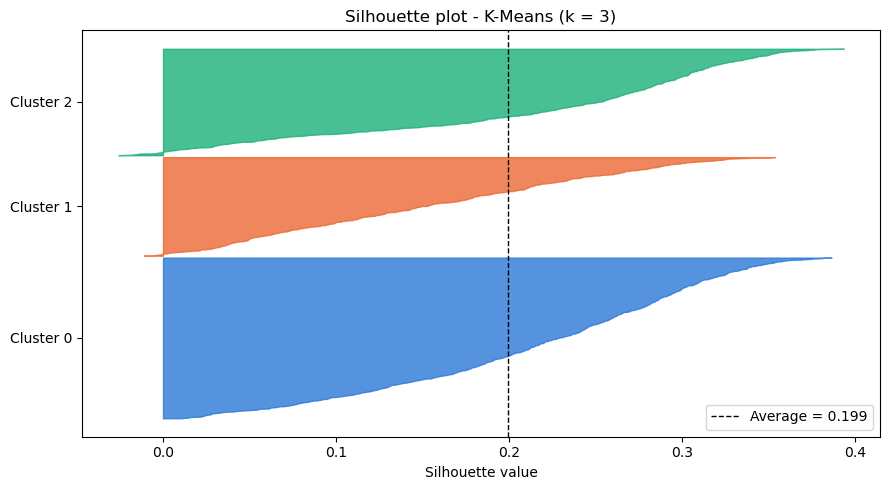

Cluster 0: mean silhouette 0.216, customers with negative silhouette: 0.0%
Cluster 1: mean silhouette 0.154, customers with negative silhouette: 2.0%
Cluster 2: mean silhouette 0.215, customers with negative silhouette: 3.3%


In [65]:
# Silhouette plot for the final model - per-customer fit to its cluster
from sklearn.metrics import silhouette_samples

sil_values = silhouette_samples(X_pca, km_labels)
fig, ax = plt.subplots(figsize=(9, 5))
y_lower = 10
tick_pos = []
for c in range(K):
    vals = np.sort(sil_values[km_labels == c])
    ax.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals, color=cluster_colors[c], alpha=0.8)
    tick_pos.append(y_lower + len(vals) / 2)
    y_lower += len(vals) + 10
ax.axvline(sil_values.mean(), color='black', linestyle='--', linewidth=1, label=f'Average = {sil_values.mean():.3f}')
ax.set_xlabel('Silhouette value')
ax.set_yticks(tick_pos)
ax.set_yticklabels([f'Cluster {c}' for c in range(K)])
ax.set_title('Silhouette plot - K-Means (k = 3)')
ax.legend()
plt.tight_layout()
plt.show()

for c in range(K):
    v = sil_values[km_labels == c]
    print(f"Cluster {c}: mean silhouette {v.mean():.3f}, customers with negative silhouette: {(v < 0).mean()*100:.1f}%")

All three clusters have a positive average silhouette (0.15-0.22), and very few customers sit closer to another cluster than their own (0-3.3%). No cluster is weak. Cluster 1 has the softest boundary, as expected for a middle segment that sits between the low-spend and high-spend groups.

## Evaluation 3: Can the segments be predicted from the original features?
If the clusters are meaningful, a classifier trained on the original (unscaled, non-PCA) features should be able to reproduce them accurately. Its feature importances also show which customer attributes define the segments.

5-fold cross-validated accuracy predicting the K-Means segment: 95.6% (+/- 0.5%)


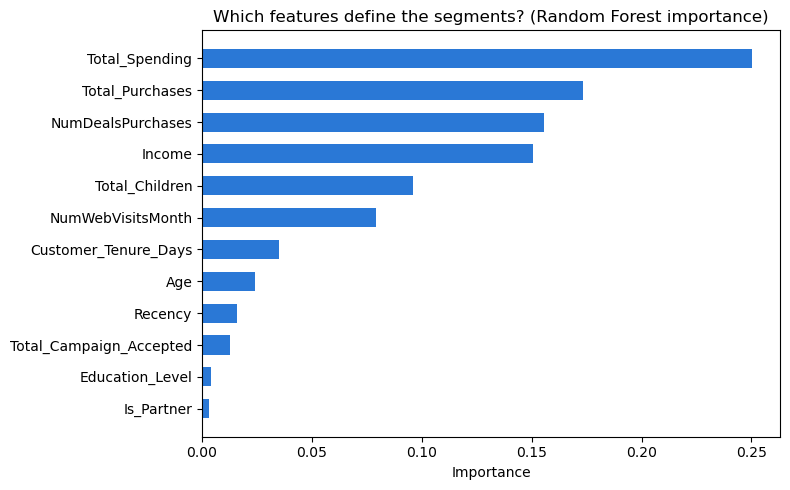

Total_Spending             0.250
Total_Purchases            0.173
NumDealsPurchases          0.155
Income                     0.151
Total_Children             0.096
NumWebVisitsMonth          0.079
Customer_Tenure_Days       0.035
Age                        0.024
Recency                    0.016
Total_Campaign_Accepted    0.013
Education_Level            0.004
Is_Partner                 0.003
dtype: float64


In [66]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_acc = cross_val_score(rf, X_model, km_labels, cv=cv, scoring='accuracy')
print(f"5-fold cross-validated accuracy predicting the K-Means segment: {cv_acc.mean()*100:.1f}% "
      f"(+/- {cv_acc.std()*100:.1f}%)")

rf.fit(X_model, km_labels)
importance = pd.Series(rf.feature_importances_, index=model_features).sort_values()
plt.figure(figsize=(8, 5))
plt.barh(importance.index, importance.values, color='#2a78d6', height=0.6)
plt.title('Which features define the segments? (Random Forest importance)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()
print(importance.sort_values(ascending=False).round(3))

A Random Forest reproduces the segments with **95.6% cross-validated accuracy** from the original features, so the segments follow clear, learnable patterns in the data.

The segments are defined mainly by **spending** (`Total_Spending`, `Total_Purchases`), **deal usage** (`NumDealsPurchases`), **income** and **number of children**. Education and partner status have almost no influence. The segments differ in buying behaviour and household stage, not in demographics.

# Cluster Profiling - Summarising the Customer Segments
Each cluster is described using the original values. Product and channel amounts are taken from the raw file (before IQR capping), so the averages reflect what customers actually spent.

In [67]:
raw = pd.read_excel("marketing_campaign.xlsx").loc[df.index]

profile_cols = ['Income', 'Age', 'Total_Children', 'Is_Partner', 'Education_Level',
                'Total_Spending', 'Total_Purchases', 'NumDealsPurchases', 'NumWebVisitsMonth',
                'Total_Campaign_Accepted', 'Recency', 'Customer_Tenure_Days']
profile = df.groupby('Cluster')[profile_cols].mean()
profile['Total_Spending_raw'] = raw[spending_cols].sum(axis=1).groupby(df['Cluster']).mean()
profile.insert(0, 'Customers', df['Cluster'].value_counts().sort_index())
profile.insert(1, 'Share_%', (profile['Customers'] / len(df) * 100).round(1))
profile['Is_Parent_%'] = (df['Total_Children'] > 0).groupby(df['Cluster']).mean() * 100
profile['Response_last_campaign_%'] = raw['Response'].groupby(df['Cluster']).mean() * 100
profile['Complained_%'] = raw['Complain'].groupby(df['Cluster']).mean() * 100

print("Cluster profile (averages):")
print(profile.round(1).T.to_string())

Cluster profile (averages):
Cluster                         0        1        2
Customers                   904.0    555.0    599.0
Share_%                      43.9     27.0     29.1
Income                    34390.9  55591.4  75046.5
Age                          42.0     48.6     46.5
Total_Children                1.2      1.3      0.2
Is_Partner                    0.6      0.7      0.6
Education_Level               1.3      1.4      1.4
Total_Spending               96.0    678.8   1177.4
Total_Purchases               5.8     16.2     19.0
NumDealsPurchases             1.8      4.0      1.2
NumWebVisitsMonth             6.3      6.2      2.9
Total_Campaign_Accepted       0.2      0.4      1.0
Recency                      48.7     50.1     48.3
Customer_Tenure_Days        305.1    449.5    334.0
Total_Spending_raw           97.3    698.8   1288.5
Is_Parent_%                  87.8     97.5     24.4
Response_last_campaign_%      8.1     14.1     27.0
Complained_%                  1.2   

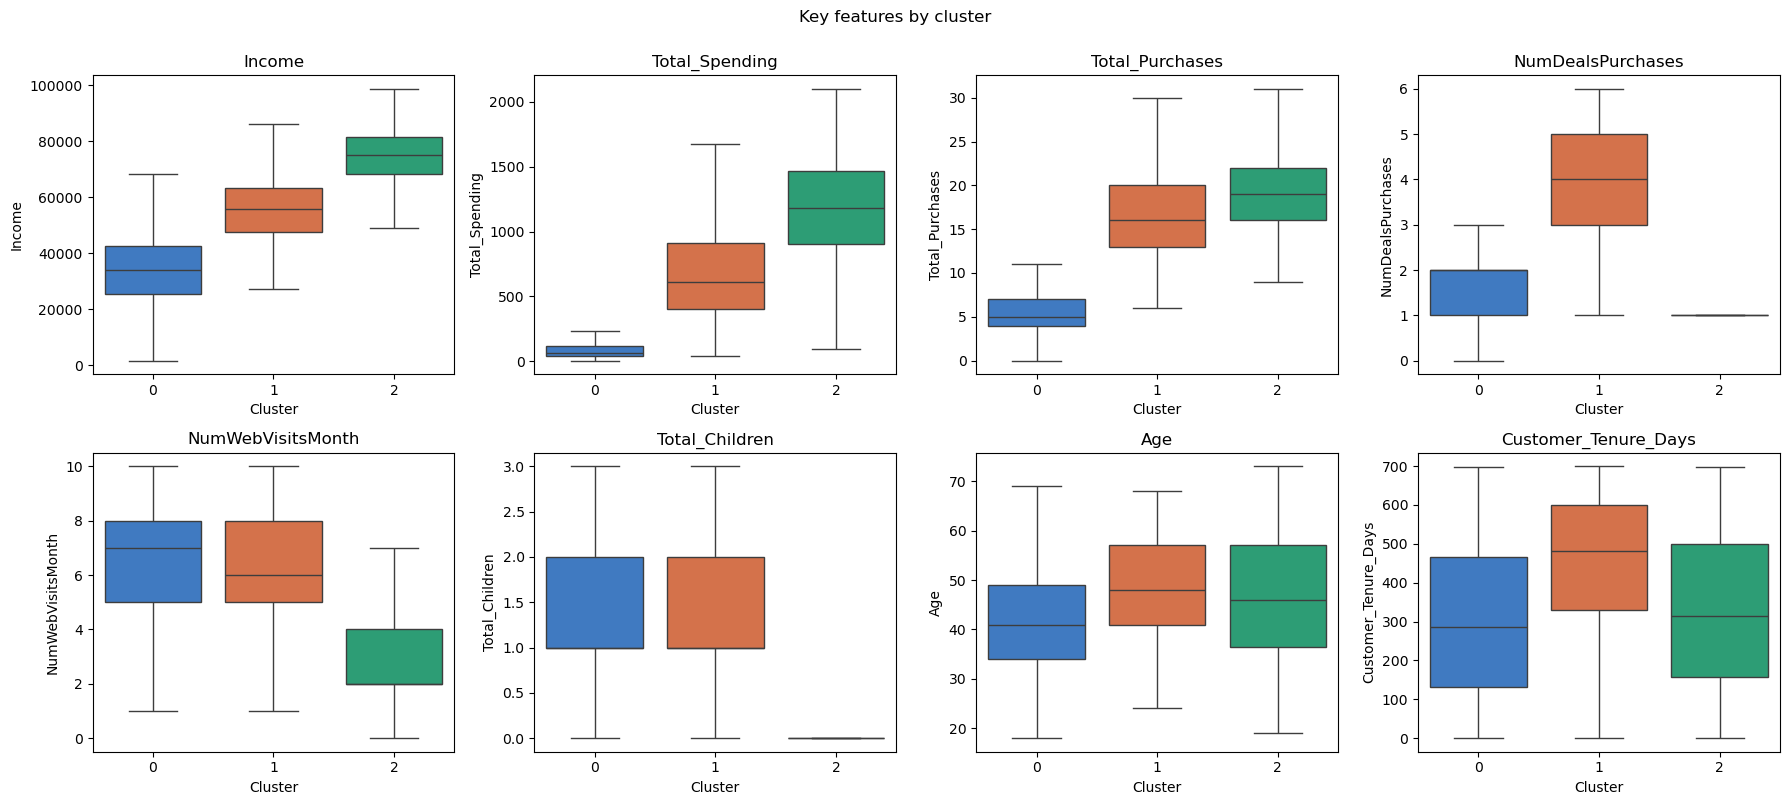

In [68]:
key_features = ['Income', 'Total_Spending', 'Total_Purchases', 'NumDealsPurchases',
                'NumWebVisitsMonth', 'Total_Children', 'Age', 'Customer_Tenure_Days']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), key_features):
    sns.boxplot(data=df, x='Cluster', y=col, palette=cluster_colors, showfliers=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('Cluster')
plt.suptitle('Key features by cluster', y=1.0)
plt.tight_layout()
plt.show()

Average spend per product over 2 years:
         Wines  Fruits   Meat  Fish  Sweet  Gold
Cluster                                         
0         40.0     5.0   22.0   8.0    6.0  16.0
1        415.0    25.0  142.0  33.0   25.0  59.0
2        599.0    59.0  411.0  87.0   62.0  71.0

Average number of purchases per channel:
         Web  Catalogue  Store  Deals
Cluster                              
0        2.2        0.5    3.2    1.8
1        6.1        3.0    7.2    4.4
2        5.2        5.5    8.3    1.2

Campaign acceptance rate (%):
         Cmp1  Cmp2  Cmp3  Cmp4  Cmp5  Last (Response)
Cluster                                               
0         0.1   0.1   6.7   1.2   0.0              8.1
1         2.7   0.9   6.7  11.0   0.9             14.1
2        19.9   3.3   8.8  14.4  23.9             27.0


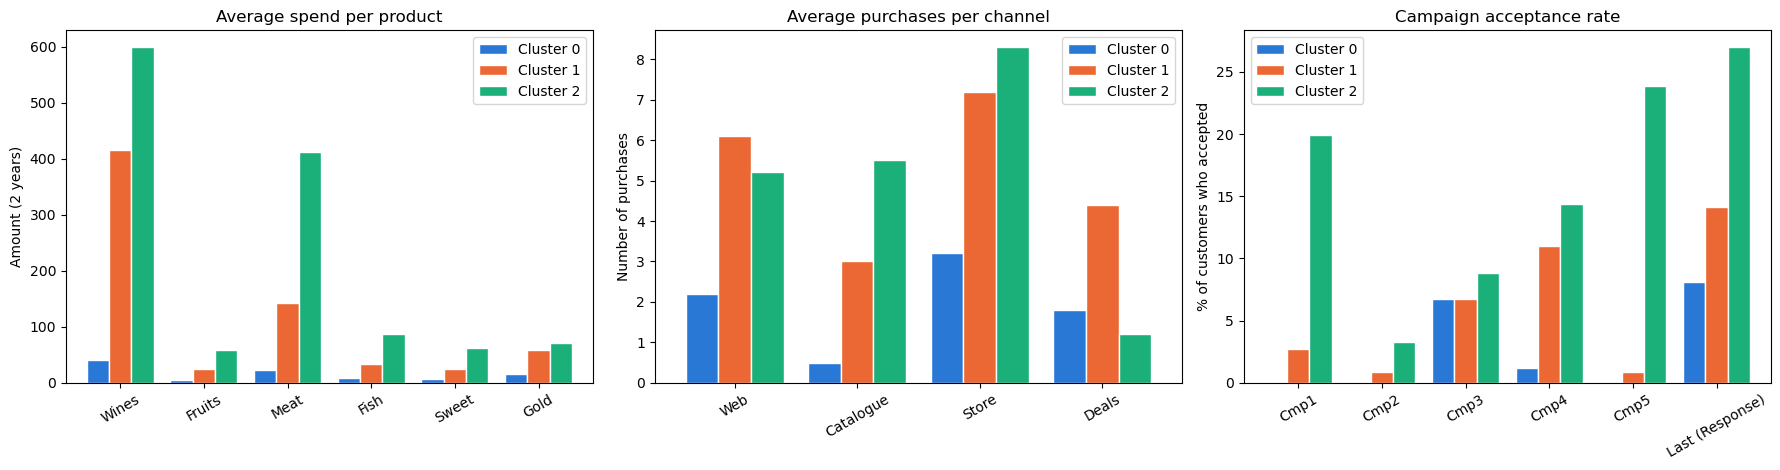

In [69]:
# Product mix - average amount spent per product (raw values)
product_mix = raw[spending_cols].groupby(df['Cluster']).mean().round(0)
product_mix.columns = [c.replace('Mnt', '').replace('Products', '').replace('Prods', '') for c in product_mix.columns]
print("Average spend per product over 2 years:")
print(product_mix)

# Channel mix - average number of purchases per channel (raw values)
channel_cols = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumDealsPurchases']
channel_mix = raw[channel_cols].groupby(df['Cluster']).mean().round(1)
channel_mix.columns = ['Web', 'Catalogue', 'Store', 'Deals']
print("\nAverage number of purchases per channel:")
print(channel_mix)

# Campaign acceptance rates
campaign_rate = (raw[campaign_cols].groupby(df['Cluster']).mean() * 100).round(1)
campaign_rate.columns = ['Cmp1', 'Cmp2', 'Cmp3', 'Cmp4', 'Cmp5', 'Last (Response)']
campaign_rate = campaign_rate[['Cmp1', 'Cmp2', 'Cmp3', 'Cmp4', 'Cmp5', 'Last (Response)']]
print("\nCampaign acceptance rate (%):")
print(campaign_rate)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, table in zip(axes, [product_mix, channel_mix, campaign_rate]):
    table.T.plot(kind='bar', ax=ax, color=cluster_colors, width=0.8, edgecolor='white', linewidth=1)
    ax.legend([f'Cluster {c}' for c in range(K)])
axes[0].set_title('Average spend per product')
axes[0].set_ylabel('Amount (2 years)')
axes[1].set_title('Average purchases per channel')
axes[1].set_ylabel('Number of purchases')
axes[2].set_title('Campaign acceptance rate')
axes[2].set_ylabel('% of customers who accepted')
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [70]:
# Demographic make-up of each cluster
edu_names = {0: 'Basic', 1: 'Graduate', 2: 'Postgraduate'}
print("Education level by cluster (% of cluster):")
print((pd.crosstab(df['Cluster'], df['Education_Level'].map(edu_names), normalize='index') * 100).round(1))
print("\nNumber of children by cluster (% of cluster):")
print((pd.crosstab(df['Cluster'], df['Total_Children'], normalize='index') * 100).round(1))
print("\nLiving with partner by cluster (% of cluster):")
print((pd.crosstab(df['Cluster'], df['Living_With'], normalize='index') * 100).round(1))

Education level by cluster (% of cluster):
Education_Level  Basic  Graduate  Postgraduate
Cluster                                       
0                  5.3      60.2          34.5
1                  0.2      55.5          44.3
2                  0.0      61.1          38.9

Number of children by cluster (% of cluster):
Total_Children     0     1     2    3
Cluster                              
0               12.2  59.8  24.9  3.1
1                2.5  64.9  29.0  3.6
2               75.6  24.0   0.3  0.0

Living with partner by cluster (% of cluster):
Living_With  Alone  Partner
Cluster                    
0             36.4     63.6
1             33.0     67.0
2             38.4     61.6


# Customer Segments - Summary

| | **Cluster 0** | **Cluster 1** | **Cluster 2** |
|---|---|---|---|
| **Segment name** | Budget-Conscious Families | Value-Seeking Established Families | Affluent Premium Buyers |
| Customers | 904 (43.9%) | 555 (27.0%) | 599 (29.1%) |
| Average income | 34,391 | 55,591 | 75,047 |
| Average spend (2 years) | 97 | 699 | 1,289 |
| Average purchases | 5.8 | 16.2 | 19.0 |
| Customers with children | 87.8% | 97.5% | 24.4% |
| Deal purchases | 1.8 | 4.0 | 1.2 |
| Web visits per month | 6.3 | 6.2 | 2.9 |
| Accepted last campaign | 8.1% | 14.1% | 27.0% |
| Average age | 42.0 | 48.6 | 46.5 |
| Days as a customer | 305 | 450 | 334 |

*Spend is from the raw data; the other columns use the cleaned (IQR-capped) values.*

### Cluster 0 - Budget-Conscious Families (44%)
- Lowest income and very low spending (about 97 over two years, under 6 purchases).
- Most have children (88%), and they are the youngest group (average age 42).
- They visit the website often (6.3 times a month) but rarely buy, and almost never use the catalogue.
- Least responsive to campaigns: 8% accepted the last campaign, and almost none accepted campaigns 1, 2 or 5.

**Recommendation:** Use low-cost channels (email, website). Promote entry-level and family-essential products, and use targeted web offers to turn their frequent visits into purchases. Avoid spending on catalogues or expensive campaigns for this group.

### Cluster 1 - Value-Seeking Established Families (27%)
- Middle income and moderate spending (about 699 over two years), mostly on wine (415).
- Nearly all are parents (97.5%), and they are the oldest group (average age 49).
- Heaviest users of discounts (4.0 deal purchases) and the most web purchases (6.1).
- Longest-standing customers (450 days on average, versus 305 and 334 for the other segments).
- Moderately responsive: 14% accepted the last campaign and 11% accepted campaign 4.

**Recommendation:** Offer discounts, bundles (family packs, wine deals) and loyalty rewards that recognise their long relationship, mainly through the website. This group has the most potential to grow toward premium spending.

### Cluster 2 - Affluent Premium Buyers (29%)
- Highest income and by far the highest spending (about 1,289 over two years, 13 times Cluster 0), led by wine (599) and meat (411). Only 29% of customers, but **62% of all spending**.
- Mostly no children at home (76%).
- Buy across all channels, with the most store and catalogue purchases, but rarely use discounts (1.2) and visit the website least.
- Most responsive to marketing: 27% accepted the last campaign, and 20-24% accepted campaigns 1 and 5.

**Recommendation:** This is the most valuable segment, so focus on retention. Use premium and loyalty programmes, personalised catalogue offers for premium wine and meat, and early access to new products. Discounts are unnecessary here.

**Across all segments:** campaign 3 had a similar acceptance rate in every cluster (6.7-8.8%), so its offer appealed broadly rather than to one segment.

                                    Customers  Avg_Income  Avg_Spending_2yrs  \
Segment                                                                        
Budget-Conscious Families                 904     34391.0               97.0   
Value-Seeking Established Families        555     55591.0              699.0   
Affluent Premium Buyers                   599     75046.0             1289.0   

                                    Last_Campaign_Response_%  
Segment                                                       
Budget-Conscious Families                                8.1  
Value-Seeking Established Families                      14.1  
Affluent Premium Buyers                                 27.0  


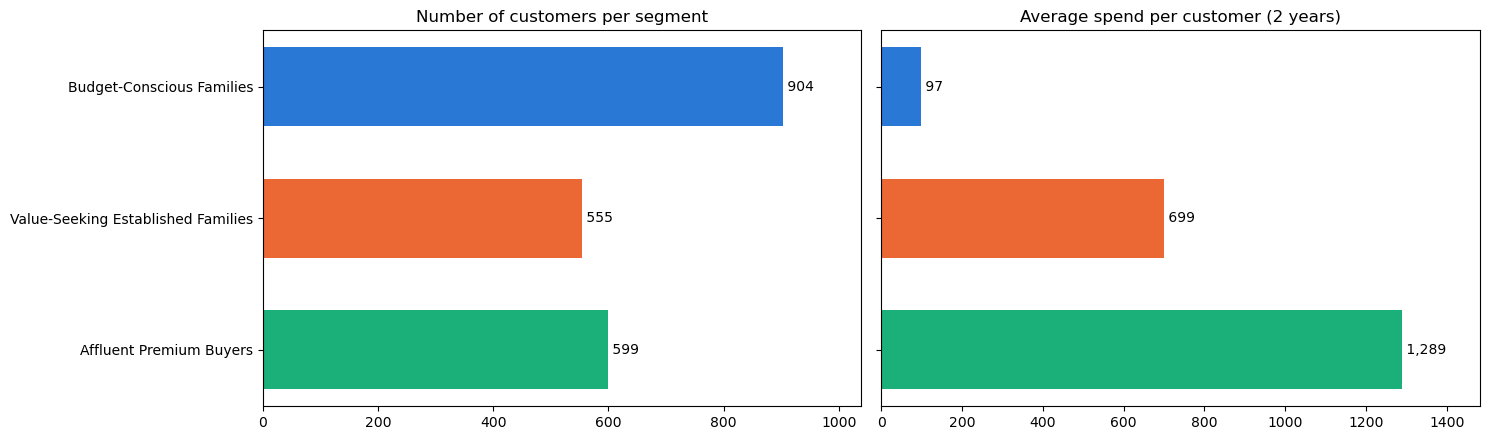


Share of total spending by segment (%):
Segment
Budget-Conscious Families              7.1
Value-Seeking Established Families    31.1
Affluent Premium Buyers               61.9
dtype: float64


In [71]:
segment_names = {
    0: 'Budget-Conscious Families',
    1: 'Value-Seeking Established Families',
    2: 'Affluent Premium Buyers'
}
df['Segment'] = df['Cluster'].map(segment_names)

segment_summary = pd.DataFrame({
    'Customers': df['Segment'].value_counts(),
    'Avg_Income': df.groupby('Segment')['Income'].mean().round(0),
    'Avg_Spending_2yrs': raw[spending_cols].sum(axis=1).groupby(df['Segment']).mean().round(0),
    'Last_Campaign_Response_%': (raw['Response'].groupby(df['Segment']).mean() * 100).round(1)
}).loc[list(segment_names.values())]
print(segment_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
seg_order = list(segment_names.values())
axes[0].barh(seg_order, segment_summary['Customers'], color=cluster_colors, height=0.6)
axes[0].set_title('Number of customers per segment')
axes[1].barh(seg_order, segment_summary['Avg_Spending_2yrs'], color=cluster_colors, height=0.6)
axes[1].set_title('Average spend per customer (2 years)')
for ax, col in zip(axes, ['Customers', 'Avg_Spending_2yrs']):
    ax.invert_yaxis()
    ax.set_xlim(0, segment_summary[col].max() * 1.15)
    for i, v in enumerate(segment_summary[col]):
        ax.text(v, i, f' {v:,.0f}', va='center')
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

share_of_revenue = raw[spending_cols].sum(axis=1).groupby(df['Segment']).sum() / raw[spending_cols].sum(axis=1).sum() * 100
print("\nShare of total spending by segment (%):")
print(share_of_revenue.loc[seg_order].round(1))

## Save the final model and clustered data
The scaler, PCA and K-Means model are saved as one pipeline, so new customers can be assigned a segment in the deployment phase with a single `predict` call.

In [72]:
import joblib
from sklearn.pipeline import Pipeline

segmentation_pipeline = Pipeline([
    ('scaler', scaler),
    ('pca', pca),
    ('kmeans', kmeans)
])

# Check the saved pipeline reproduces the labels
assert (segmentation_pipeline.predict(X_model) == km_labels).all()

joblib.dump(segmentation_pipeline, 'customer_segmentation_model.pkl')
df.to_csv('customers_with_segments.csv', index=False)
print("Saved: customer_segmentation_model.pkl")
print("Saved: customers_with_segments.csv", df.shape)
print("Model input features (in this order):", model_features)

Saved: customer_segmentation_model.pkl
Saved: customers_with_segments.csv (2058, 37)
Model input features (in this order): ['Age', 'Income', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth', 'Total_Spending', 'Total_Purchases', 'Total_Children', 'Total_Campaign_Accepted', 'Customer_Tenure_Days', 'Education_Level', 'Is_Partner']


In [73]:
%whos

Variable                   Type                       Data/Info
---------------------------------------------------------------
AgglomerativeClustering    type                       <class 'sklearn.cluster._<...>AgglomerativeClustering'>
ColumnTransformer          ABCMeta                    <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
GaussianMixture            ABCMeta                    <class 'sklearn.mixture._<...>mixture.GaussianMixture'>
IQR                        float64                    4.0
K                          int                        3
KMeans                     ABCMeta                    <class 'sklearn.cluster._kmeans.KMeans'>
OneHotEncoder              type                       <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
PCA                        ABCMeta                    <class 'sklearn.decomposition._pca.PCA'>
Pipeline                   ABCMeta                    <class 'sklearn.pipeline.Pipeline'>
Q1                         float64    

In [74]:
print("SEGMENTATION PIPELINE : ")
print(segmentation_pipeline)

print("\nMODEL FEATURES :")
print (model_features)

print("\nKMEANS MODEL :")
print(kmeans)

print("\n SCALER :")
print(scaler)

print("\nPREPROCESSOR :")
print(preprocessor)

SEGMENTATION PIPELINE : 
Pipeline(steps=[('scaler', StandardScaler()),
                ('pca', PCA(n_components=7, random_state=42)),
                ('kmeans', KMeans(n_clusters=3, n_init=20, random_state=42))])

MODEL FEATURES :
['Age', 'Income', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth', 'Total_Spending', 'Total_Purchases', 'Total_Children', 'Total_Campaign_Accepted', 'Customer_Tenure_Days', 'Education_Level', 'Is_Partner']

KMEANS MODEL :
KMeans(n_clusters=3, n_init=20, random_state=42)

 SCALER :
StandardScaler()

PREPROCESSOR :
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'Income', 'Recency',
                                  'NumDealsPurchases', 'NumWebVisitsMonth',
                                  'Total_Spen

In [75]:
import joblib

# Save the complete trained pipeline
joblib.dump(
    segmentation_pipeline,
    "customer_segmentation_pipeline.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [76]:
import joblib

loaded_pipeline = joblib.load(
    "customer_segmentation_pipeline.pkl"
)

print(loaded_pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('pca', PCA(n_components=7, random_state=42)),
                ('kmeans', KMeans(n_clusters=3, n_init=20, random_state=42))])


In [77]:
print("Preprocessor:")
print(preprocessor)

print("\nSegmentation Pipeline:")
print(segmentation_pipeline)

print("\nModel Features:")
print(model_features)

print("\nOriginal Data Columns:")
print(df.columns.tolist())

Preprocessor:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'Income', 'Recency',
                                  'NumDealsPurchases', 'NumWebVisitsMonth',
                                  'Total_Spending', 'Total_Purchases',
                                  'Total_Children', 'Total_Campaign_Accepted',
                                  'Customer_Tenure_Days']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                        

In [78]:
for i, code in enumerate(In):
    if "X_model" in code or "Education_Level" in code or "Is_Partner" in code:
        print(f"\n--- Cell {i} ---")
        print(code)


--- Cell 53 ---
df['Living_With'] = df['Marital_Status'].replace({
    'Married': 'Partner', 'Together': 'Partner',
    'Single': 'Alone', 'Divorced': 'Alone', 'Widow': 'Alone',
    'Alone': 'Alone', 'Absurd': 'Alone', 'YOLO': 'Alone'
})
df['Is_Partner'] = (df['Living_With'] == 'Partner').astype(int)

df['Education_Level'] = df['Education'].map({
    'Basic': 0, '2n Cycle': 1, 'Graduation': 1, 'Master': 2, 'PhD': 2
})

print(df['Living_With'].value_counts())
print()
print(df['Education_Level'].value_counts().sort_index())
print("\nMissing Education_Level values:", df['Education_Level'].isna().sum())

--- Cell 54 ---
from sklearn.preprocessing import StandardScaler

model_features = [
    'Age', 'Income', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth',
    'Total_Spending', 'Total_Purchases', 'Total_Children',
    'Total_Campaign_Accepted', 'Customer_Tenure_Days',
    'Education_Level', 'Is_Partner'
]

X_model = df[model_features].copy()
scaler = StandardScaler()
X_scaled = scaler

In [79]:
keywords = [
    "Age",
    "Total_Spending",
    "Total_Purchases",
    "Total_Children",
    "Total_Campaign_Accepted",
    "Customer_Tenure_Days"
]

for i, code in enumerate(In):
    if any(keyword in code for keyword in keywords):
        print(f"\n--- Cell {i} ---")
        print(code)


--- Cell 21 ---
# The original Marketing Campaign dataset does not contain an Age column.
# Age is calculated from Year_Birth in the next section.
if 'Year_Birth' in df.columns:
    print(df[['Year_Birth']].head())
else:
    raise KeyError("Required column 'Year_Birth' is missing. Check the dataset file.")

--- Cell 22 ---
# Calculate customer age using 2014 as reference year

df['Year_Birth'] = pd.to_numeric(
    df['Year_Birth'], errors='coerce'
)

df['Age'] = 2014 - df['Year_Birth']

# Handle invalid ages
df.loc[
    (df['Age'] <= 0) | (df['Age'] > 100),
    'Age'
] = np.nan

# Fill missing age values
df['Age'] = df['Age'].fillna(
    df['Age'].median()
)

print(df['Age'].describe())

--- Cell 23 ---
# Age has already been validated and missing/invalid ages handled in the previous cell.
print('Missing Age values:', df['Age'].isna().sum())

--- Cell 25 ---
# Detect outliers only in numerical columns currently available.
outlier_cols = [
    'Income', 'Age', 'Recency', 'NumDealsPurch

# Model Building & Evaluation - Conclusion

1. **Data fixes:** 182 duplicate customers removed (2,058 remain). Marital status grouped into Partner / Alone, education into 3 levels, and 12 features standardised.
2. **PCA** reduced 12 features to 7 components, keeping 85.3% of the variance.
3. **Number of clusters:** k = 3 chosen using the elbow method, silhouette, Davies-Bouldin and Calinski-Harabasz scores, and a bootstrap stability test (mean ARI 0.946 for k = 3 vs 0.849 for k = 4).
4. **Model comparison:** K-Means, Agglomerative (Ward) and Gaussian Mixture were compared. **K-Means was best on every measure** (silhouette 0.199, Davies-Bouldin 1.743, Calinski-Harabasz 585.7), and Agglomerative clustering found similar groups (ARI 0.615).
5. **Validation:** a Random Forest reproduces the segments with 95.6% accuracy. The segments are driven by spending, deal usage, income and number of children.
6. **Three customer segments:**
   - **Budget-Conscious Families** (44%): low income, low spend, frequent web browsers who rarely buy.
   - **Value-Seeking Established Families** (27%): middle income, deal-driven parents, the longest-standing customers.
   - **Affluent Premium Buyers** (29%): high income, high spend, few children, the most responsive to campaigns. They generate 62% of all spending, while Budget-Conscious Families (44% of customers) generate only 7%.
7. **Saved for deployment:** `customer_segmentation_model.pkl` (scaler + PCA + K-Means pipeline) and `customers_with_segments.csv`.

**Limitations:** the silhouette score (~0.2) shows the segments have soft boundaries, so customers near a boundary could reasonably belong to either neighbouring segment. The data covers customers who enrolled in 2012-2014, so the segments should be re-checked on newer data.